# 01 — Exploratory Data Analysis (EDA)

**Project:** Crop Yield Prediction and Forecasting Using Agricultural Data and Machine Learning  
**Dataset:** Historical Indian district–crop records, 1966–2017  
**Target:** Yield (kg/ha)

This notebook examines crop-wise yield differences, trends, environmental variables, soil, agricultural inputs, and potential data-quality concerns. The original CSV is not modified. Statistical associations below **do not establish causal effects or future forecasting ability**.

**Research workflow:** Audit → EDA → Preprocessing → Feature Engineering → Feature Selection → Modeling → Evaluation. Feature engineering and feature selection will be performed in separate notebooks.

---

## 1. Imports and Dataset Loading

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Project directories
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw" / "crop_yield_dataset.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Report directories
REPORTS_FIG_DIR = PROJECT_ROOT / "reports" / "figures" / "eda"
REPORTS_TAB_DIR = PROJECT_ROOT / "reports" / "tables" / "eda"

REPORTS_FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_TAB_DIR.mkdir(parents=True, exist_ok=True)

# Plot appearance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 6)

# Random seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("EDA environment ready!")
print("Project folder:", PROJECT_ROOT)

EDA environment ready!
Project folder: D:\crop_yield_prediction


In [2]:

# Load the dataset
csv_path = PROJECT_ROOT / "data" / "raw" / "crop_yield_dataset.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Dataset not found: {csv_path}. Run this notebook from the project root or notebooks/.")

df = pd.read_csv(csv_path)

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")


Dataset loaded: 198,369 rows x 15 columns



## 2. Target Variable Analysis: Yield

The prediction target is **agricultural crop yield in kilograms per hectare ($\text{kg/ha}$)**. 
We evaluate parametric (mean, standard deviation, skewness, kurtosis) and non-parametric (median, IQR, quantiles) statistics across the full dataset.


In [3]:

# Analyze the distribution of crop yield
y = df["Yield"]
y_log = np.log1p(y)

target_stats = pd.DataFrame({
    "Raw Yield": [
        y.mean(),
        y.median(),
        y.std(),
        y.skew(),
        y.kurt()
    ],
    "Log1p Yield": [
        y_log.mean(),
        y_log.median(),
        y_log.std(),
        y_log.skew(),
        y_log.kurt()
    ]
}, index=[
    "Mean",
    "Median",
    "Standard Deviation",
    "Skewness",
    "Kurtosis"
])

display(target_stats.round(2))

# Save the summary statistics
target_stats.to_csv(
    REPORTS_TAB_DIR / "02_target_summary_statistics.csv"
)


,Raw Yield,Log1p Yield
Mean,1239.22,6.67
Median,800.00,6.69
Standard Deviation,1515.32,0.95
Skewness,3.74,-0.10
Kurtosis,26.38,0.96


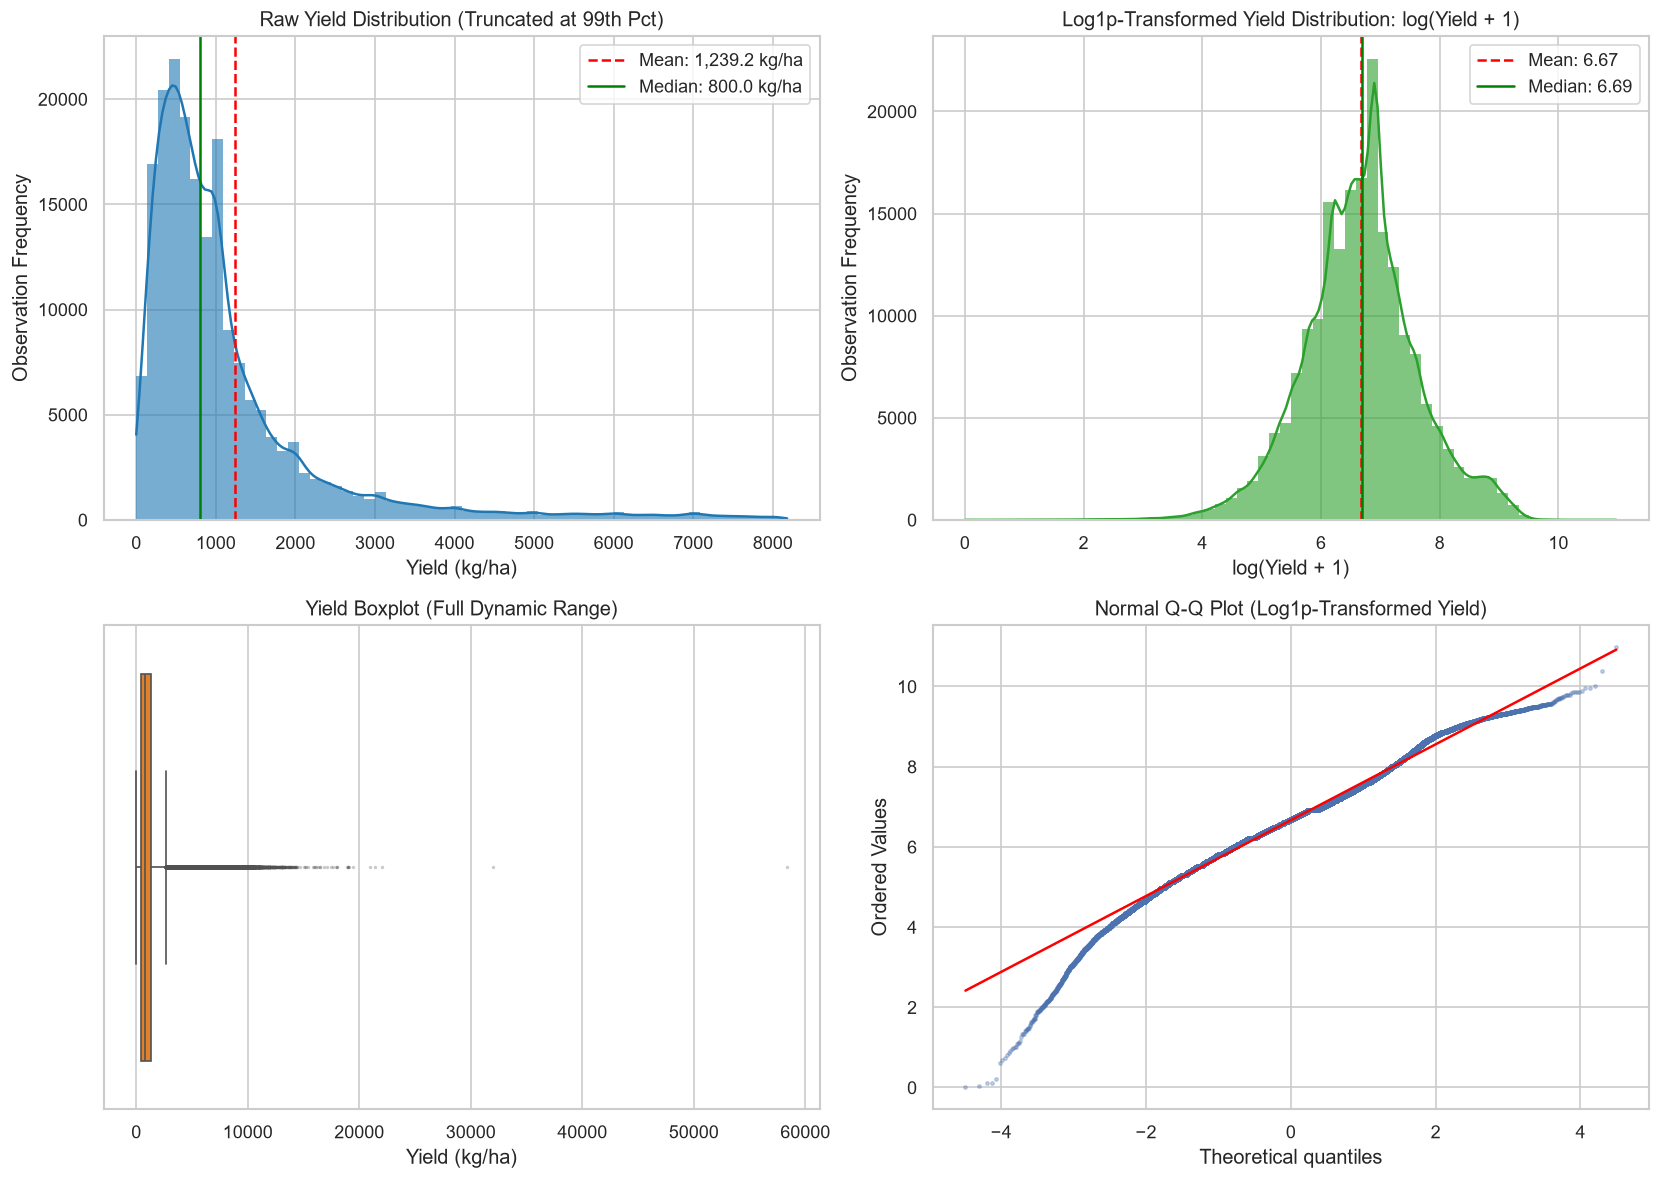

Figure saved to: D:\crop_yield_prediction\reports\figures\eda\fig01_target_distribution.png


In [4]:
# Figure 1: 4-Panel Target Diagnostic
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Raw Yield Histogram + KDE (truncated at 99th percentile for readability)
p99 = y.quantile(0.99)
sns.histplot(y[y <= p99], bins=60, kde=True, ax=axes[0, 0], color="#1f77b4", edgecolor="none", alpha=0.6)
axes[0, 0].axvline(y.mean(), color="red", linestyle="--", lw=1.5, label=f"Mean: {y.mean():,.1f} kg/ha")
axes[0, 0].axvline(y.median(), color="green", linestyle="-", lw=1.5, label=f"Median: {y.median():,.1f} kg/ha")
axes[0, 0].set_title("Raw Yield Distribution (Truncated at 99th Pct)")
axes[0, 0].set_xlabel("Yield (kg/ha)")
axes[0, 0].set_ylabel("Observation Frequency")
axes[0, 0].legend()

# 2. Log1p Transformed Yield Distribution
sns.histplot(y_log, bins=60, kde=True, ax=axes[0, 1], color="#2ca02c", edgecolor="none", alpha=0.6)
axes[0, 1].axvline(y_log.mean(), color="red", linestyle="--", lw=1.5, label=f"Mean: {y_log.mean():.2f}")
axes[0, 1].axvline(y_log.median(), color="green", linestyle="-", lw=1.5, label=f"Median: {y_log.median():.2f}")
axes[0, 1].set_title("Log1p-Transformed Yield Distribution: log(Yield + 1)")
axes[0, 1].set_xlabel("log(Yield + 1)")
axes[0, 1].set_ylabel("Observation Frequency")
axes[0, 1].legend()

# 3. Target Boxplot (Full Range with Outlier Extent)
sns.boxplot(x=y, ax=axes[1, 0], color="#ff7f0e", flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
axes[1, 0].set_title("Yield Boxplot (Full Dynamic Range)")
axes[1, 0].set_xlabel("Yield (kg/ha)")

# 4. Normal Q-Q Plot of Log1p Yield
stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_markersize(2.0)
axes[1, 1].get_lines()[0].set_alpha(0.3)
axes[1, 1].get_lines()[1].set_color("red")
axes[1, 1].set_title("Normal Q-Q Plot (Log1p-Transformed Yield)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig01_target_distribution.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Figure saved to: {fig_path}")


---

## 3. Crop-Wise Yield Analysis



In [5]:
# Compute complete descriptive statistics for all 21 crops
crop_summary = df.groupby("Crop")["Yield"].agg(
    Record_Count="count",
    Min="min",
    Q25=lambda s: s.quantile(0.25),
    Median="median",
    Mean="mean",
    Q75=lambda s: s.quantile(0.75),
    Q95=lambda s: s.quantile(0.95),
    Max="max",
    Std="std"
)
crop_summary["IQR"] = crop_summary["Q75"] - crop_summary["Q25"]
crop_summary["CV (%)"] = ((crop_summary["Std"] / crop_summary["Mean"]) * 100).round(2)
crop_summary = crop_summary.sort_values("Median", ascending=False)

crop_summary.to_csv(REPORTS_TAB_DIR / "03_crop_yield_statistics.csv")
display(crop_summary[["Record_Count", "Min", "Median", "Mean", "Max", "IQR", "CV (%)"]].round(2))


,Record_Count,Min,Median,Mean,Max,IQR,CV (%)
Crop,,,,,,,
Sugarcane,13264,23.53,5200.00,5385.25,22062.30,3537.45,49.63
Wheat,13227,46.11,1555.98,1761.17,5541.52,1276.21,54.36
Rice,14476,9.12,1433.62,1609.66,5653.83,1274.44,55.92
Maize,13615,3.35,1302.43,1611.20,21428.57,1082.89,70.68
Barley,7673,14.41,1270.27,1492.29,14441.86,937.18,55.93
Groundnut,11796,3.77,970.54,1021.80,8500.00,548.81,49.42
Soybean,4023,83.33,937.50,956.09,3884.06,520.13,44.08
Finger Millet,5615,21.44,888.89,975.02,9286.86,606.54,55.47
Sunflower,4846,22.32,850.10,912.22,4282.05,718.75,54.96


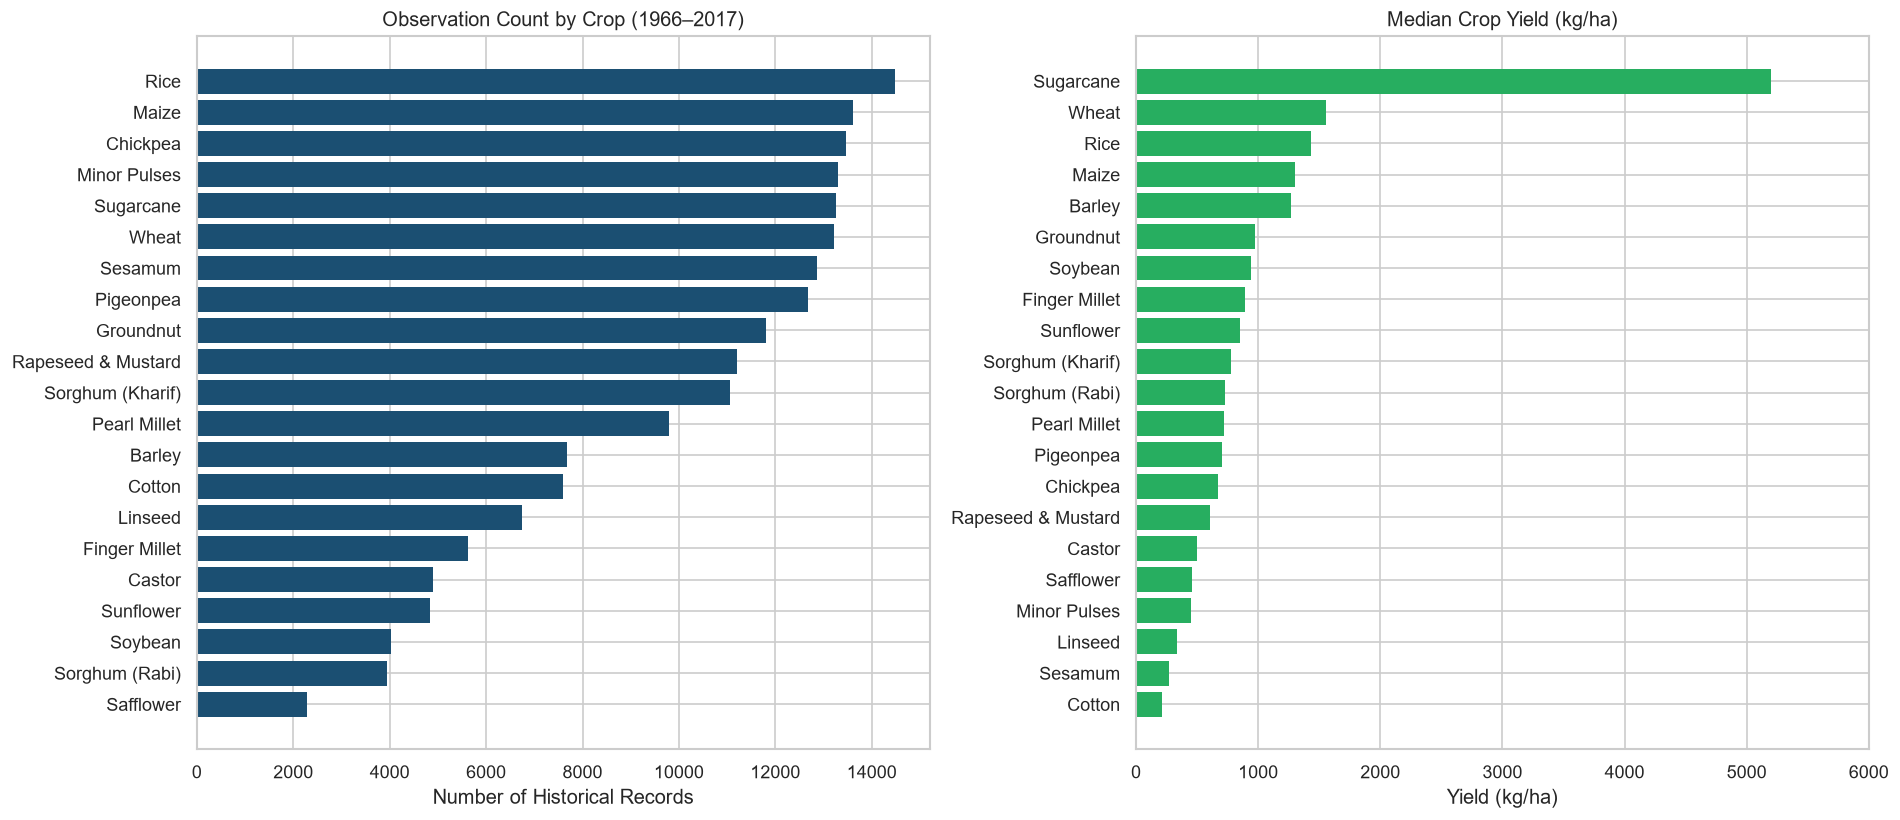

In [6]:
# Figure 2: Observation Count and Median Yield across all 21 Crops
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot A: Record Counts
crop_counts = df["Crop"].value_counts().sort_values(ascending=True)
axes[0].barh(crop_counts.index, crop_counts.values, color="#1b4f72", edgecolor="none")
axes[0].set_title("Observation Count by Crop (1966–2017)")
axes[0].set_xlabel("Number of Historical Records")

# Subplot B: Median Yield by Crop
crop_medians = crop_summary["Median"].sort_values(ascending=True)
axes[1].barh(crop_medians.index, crop_medians.values, color="#27ae60", edgecolor="none")
axes[1].set_title("Median Crop Yield (kg/ha)")
axes[1].set_xlabel("Yield (kg/ha)")
axes[1].set_xlim(0, 6000)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig02_crop_yield_bars.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


C:\Users\PHITESH\AppData\Local\Temp\ipykernel_8776\4158432785.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Crop", y="Yield", order=order, palette="tab20", flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})


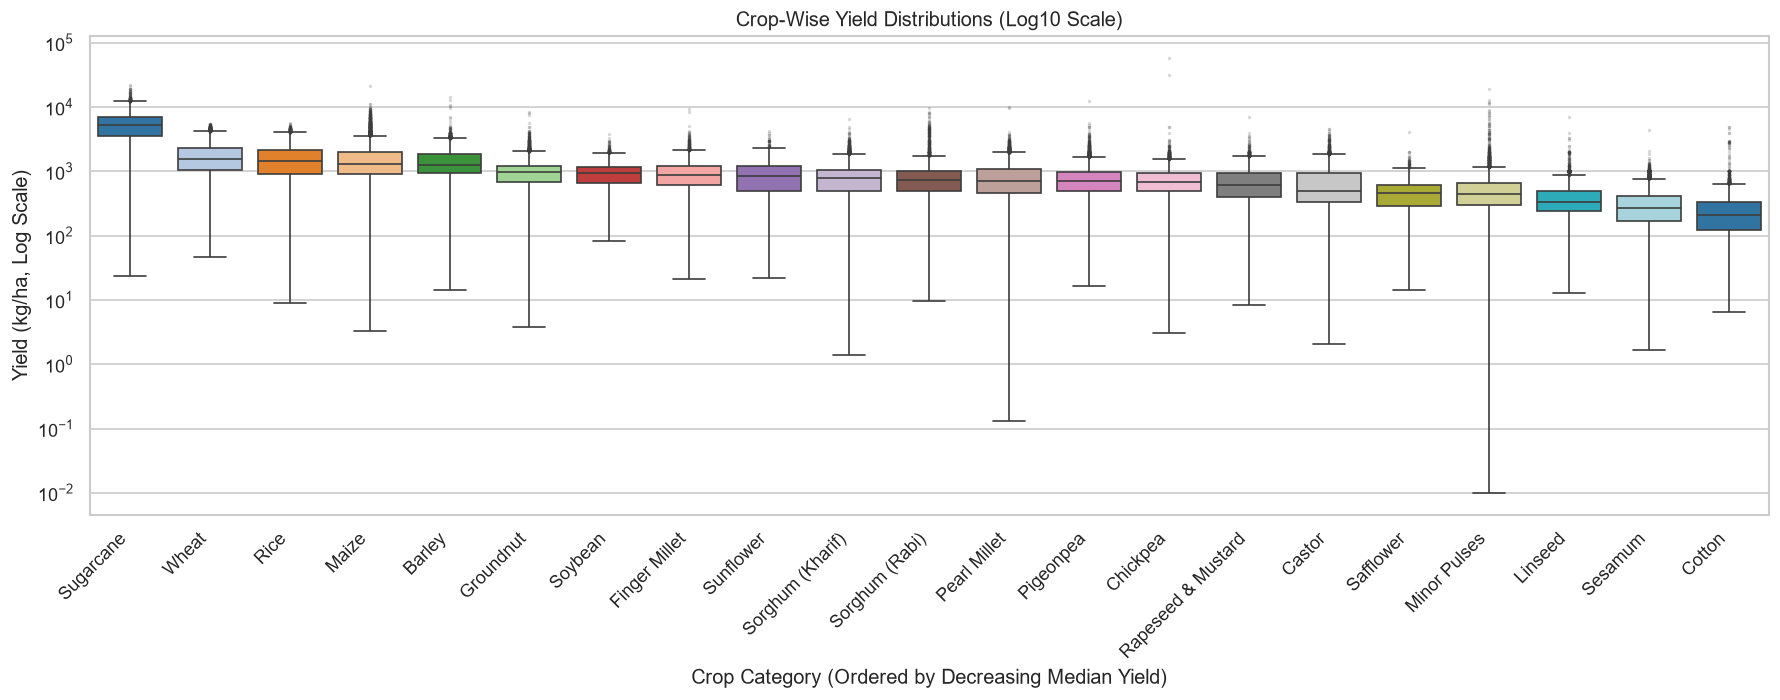

In [7]:
# Figure 3: Log-Scaled Boxplots for all 21 Crops
plt.figure(figsize=(15, 6))
order = crop_summary.index.tolist()
sns.boxplot(data=df, x="Crop", y="Yield", order=order, palette="tab20", flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})
plt.title("Crop-Wise Yield Distributions (Log10 Scale)")
plt.xlabel("Crop Category (Ordered by Decreasing Median Yield)")
plt.ylabel("Yield (kg/ha, Log Scale)")
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig03_crop_yield_boxplots.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


## Seasonal Analysis

We compare season-level distributions while accounting for different crops in each category.

In [8]:
# Crosstabulation of Crop vs Season to verify exclusivity
crosstab_crop_season = pd.crosstab(df["Crop"], df["Season"])
crosstab_crop_season.to_csv(REPORTS_TAB_DIR / "04_seasonal_crop_composition.csv")

# Compute Seasonal Yield Aggregations
season_summary = df.groupby("Season")["Yield"].agg(
    Record_Count="count",
    Mean_Yield="mean",
    Median_Yield="median",
    Std_Yield="std",
    IQR_Yield=lambda s: s.quantile(0.75) - s.quantile(0.25)
)
display(season_summary.round(2))
print("--- Crop vs Season Exclusivity Check (Sample Rows) ---")
display(crosstab_crop_season.head(10))


,Record_Count,Mean_Yield,Median_Yield,Std_Yield,IQR_Yield
Season,,,,,
Kharif,108395,951.61,777.78,786.34,797.56
Rabi,58562,1021.94,796.88,851.19,780.30
Whole Year,31412,2636.78,1000.00,2947.84,4093.46


--- Crop vs Season Exclusivity Check (Sample Rows) ---


Season,Kharif,Rabi,Whole Year
Crop,,,
Barley,0,7673,0
Castor,4891,0,0
Chickpea,0,13473,0
Cotton,7600,0,0
Finger Millet,5615,0,0
Groundnut,11796,0,0
Linseed,0,6755,0
Maize,13615,0,0
Minor Pulses,0,0,13302


In [9]:
# Check how many seasons each crop belongs to
seasons_per_crop = (crosstab_crop_season > 0).sum(axis=1)

print("Total crops:", len(seasons_per_crop))
print("Crops with exactly one season:", (seasons_per_crop == 1).sum())
print("Crops with multiple seasons:", (seasons_per_crop > 1).sum())

Total crops: 21
Crops with exactly one season: 21
Crops with multiple seasons: 0


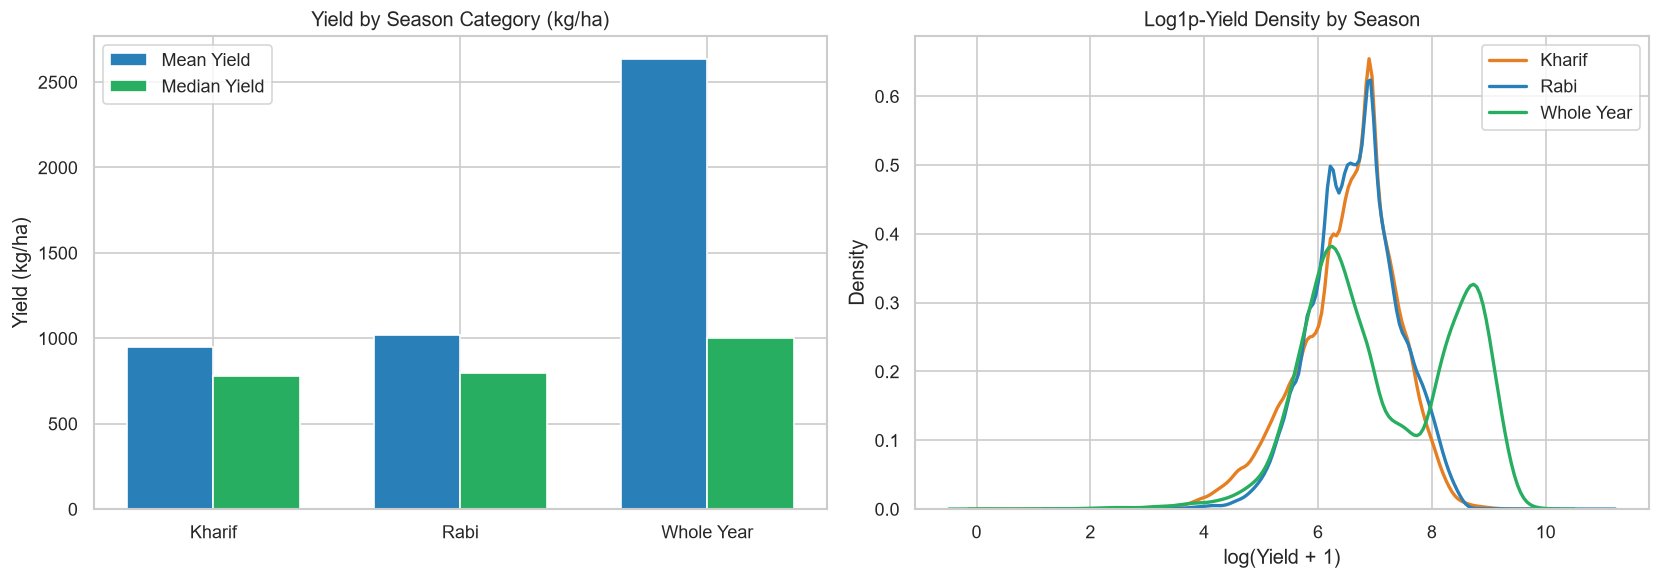

In [10]:
# Figure 4: Seasonal Analysis & Confounding Structure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: Seasonal Mean vs Median Yield
seasons = season_summary.index
x_pos = np.arange(len(seasons))
width = 0.35

axes[0].bar(x_pos - width/2, season_summary["Mean_Yield"], width, label="Mean Yield", color="#2980b9")
axes[0].bar(x_pos + width/2, season_summary["Median_Yield"], width, label="Median Yield", color="#27ae60")
axes[0].set_title("Yield by Season Category (kg/ha)")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(seasons)
axes[0].set_ylabel("Yield (kg/ha)")
axes[0].legend()

# Subplot B: Log-scaled distribution by Season
for s, col in zip(["Kharif", "Rabi", "Whole Year"], ["#e67e22", "#2980b9", "#27ae60"]):
    sns.kdeplot(np.log1p(df[df["Season"] == s]["Yield"]), label=s, ax=axes[1], color=col, lw=2.0)
axes[1].set_title("Log1p-Yield Density by Season")
axes[1].set_xlabel("log(Yield + 1)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig04_seasonal_analysis.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


## Temporal Yield Trends (1966–2017)

We examine annual observation coverage, overall yield trends and crop-specific trajectories.

In [11]:
# Annual aggregations
annual_summary = df.groupby("Year").agg(
    Record_Count=("Yield", "count"),
    Mean_Yield=("Yield", "mean"),
    Median_Yield=("Yield", "median"),
    Std_Yield=("Yield", "std"),
    Fertilizer_Mean=("Fertilizer", "mean"),
    Rainfall_Mean=("Rainfall", "mean")
).reset_index()

annual_summary.to_csv(REPORTS_TAB_DIR / "05_annual_yield_trends.csv", index=False)
display(annual_summary.iloc[[0, 10, 20, 30, 40, 50]])


,Year,Record_Count,Mean_Yield,Median_Yield,Std_Yield,Fertilizer_Mean,Rainfall_Mean
0,1966,3213,812.233838,493.150,1288.533181,5.156203,863.314472
10,1976,3733,1015.172140,632.810,1369.311389,20.982995,1049.525690
20,1986,3707,1127.226442,714.290,1482.629091,50.781721,905.696223
30,1996,4024,1313.463186,894.915,1479.942644,72.109182,1096.200025
40,2006,4185,1345.344691,883.610,1537.168555,114.054901,1050.320287
50,2016,3977,1691.696266,1112.080,1751.190386,131.488371,1042.243098


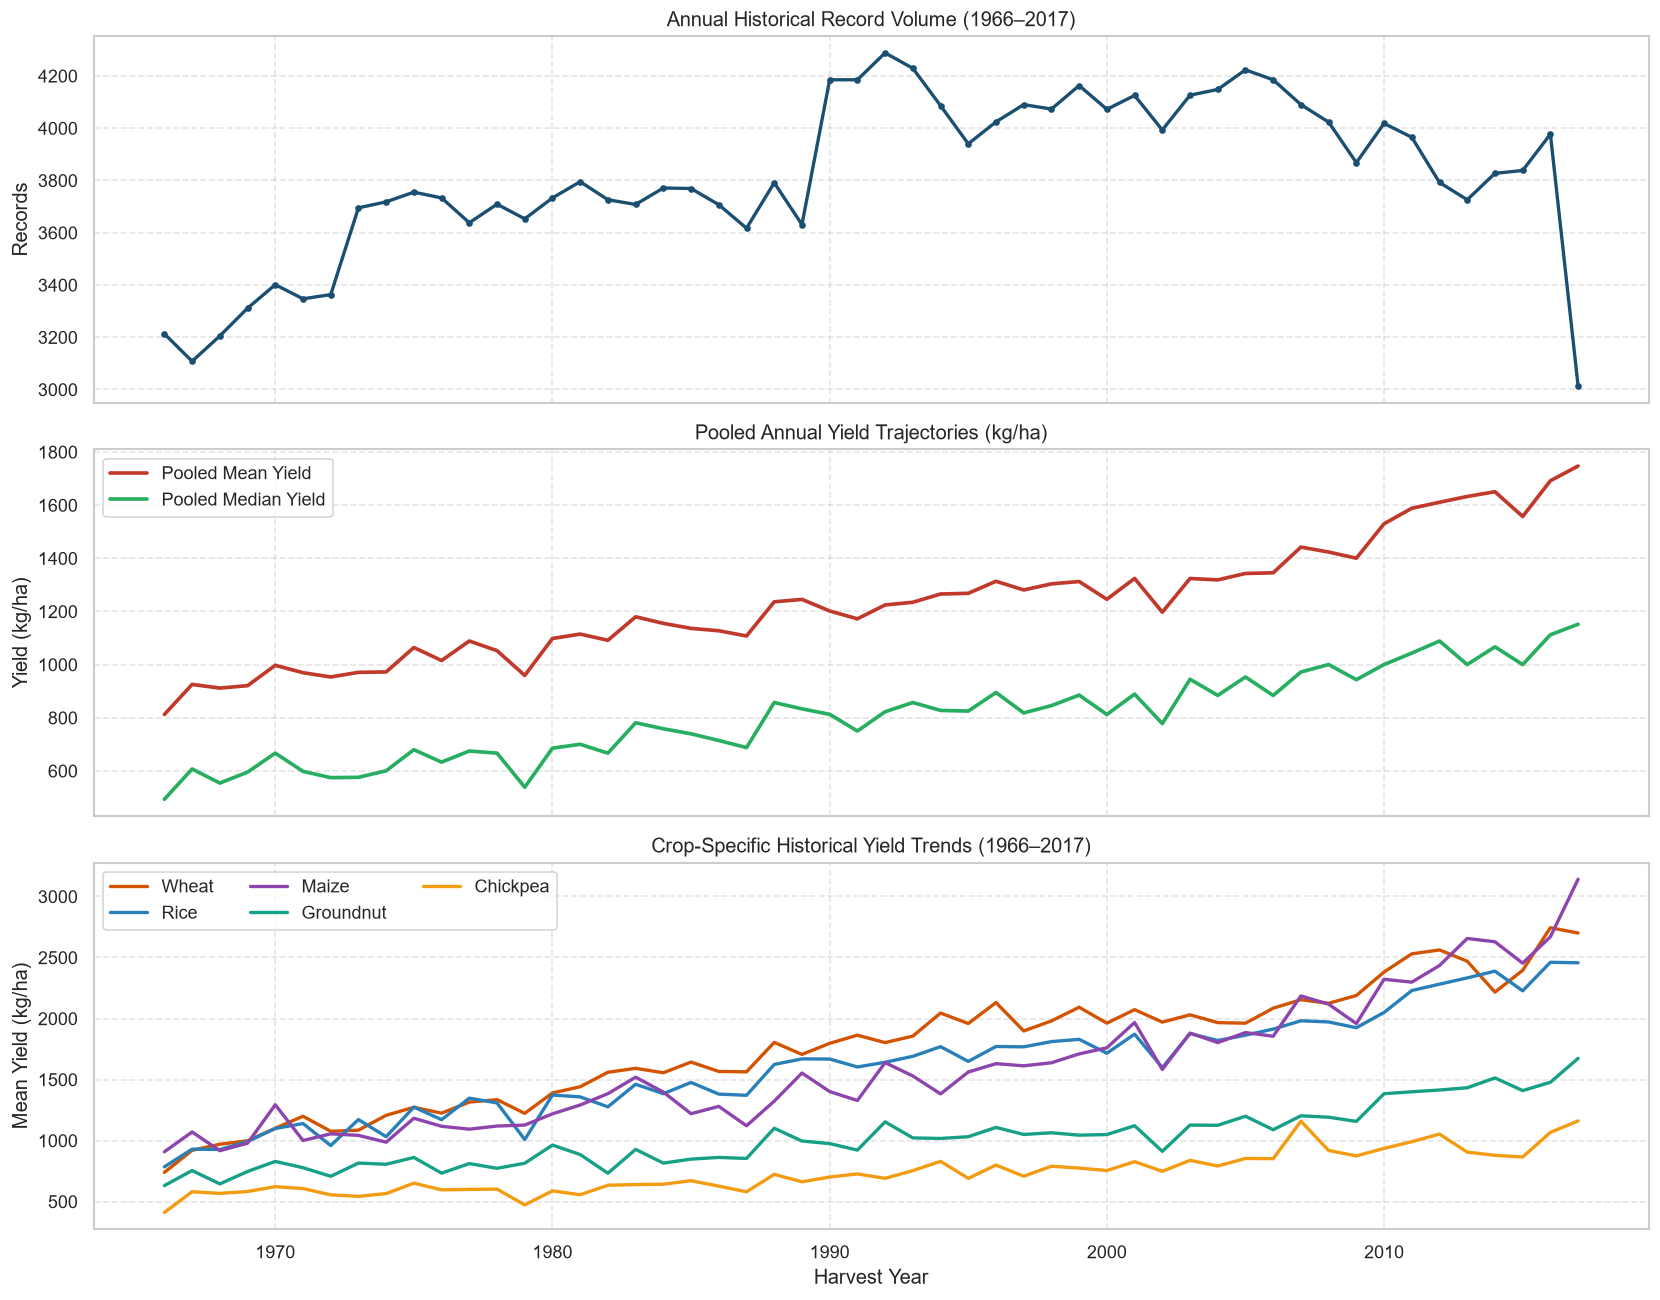

In [12]:
# Figure 5: 3-Panel Temporal Diagnostic
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# 1. Annual observation counts
axes[0].plot(annual_summary["Year"], annual_summary["Record_Count"], marker="o", color="#1b4f72", lw=2.0, markersize=3)
axes[0].set_title("Annual Historical Record Volume (1966–2017)")
axes[0].set_ylabel("Records")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Pooled Mean vs Median Yield over Time
axes[1].plot(annual_summary["Year"], annual_summary["Mean_Yield"], label="Pooled Mean Yield", color="#c0392b", lw=2.2)
axes[1].plot(annual_summary["Year"], annual_summary["Median_Yield"], label="Pooled Median Yield", color="#27ae60", lw=2.2)
axes[1].set_title("Pooled Annual Yield Trajectories (kg/ha)")
axes[1].set_ylabel("Yield (kg/ha)")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Longitudinal Trends for Selected Major Crops
benchmark_crops = ["Wheat", "Rice", "Maize", "Groundnut", "Chickpea"]
crop_colors = ["#d35400", "#2980b9", "#8e44ad", "#16a085", "#f39c12"]

for c, col in zip(benchmark_crops, crop_colors):
    crop_yr = df[df["Crop"] == c].groupby("Year")["Yield"].mean()
    axes[2].plot(crop_yr.index, crop_yr.values, label=c, color=col, lw=2.0)

axes[2].set_title("Crop-Specific Historical Yield Trends (1966–2017)")
axes[2].set_xlabel("Harvest Year")
axes[2].set_ylabel("Mean Yield (kg/ha)")
axes[2].legend(loc="upper left", ncol=3)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig05_temporal_trends.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


## Geographic Analysis

We compare geographic coverage and yields. Pooled state averages may reflect differences in crop composition.

In [13]:
# Extract State from Region string ("District, State")
df["State"] = df["Region"].apply(lambda s: s.split(", ")[-1] if ", " in str(s) else str(s))

df["State"] = df["State"].replace({"AndhraPradesh": "Andhra Pradesh"})

state_summary = df.groupby("State").agg(
    Record_Count=("Yield", "count"),
    District_Count=("Region", "nunique"),
    Mean_Yield=("Yield", "mean"),
    Median_Yield=("Yield", "median"),
    Mean_Rainfall=("Rainfall", "mean"),
    Mean_Fertilizer=("Fertilizer", "mean")
).sort_values("Record_Count", ascending=False).reset_index()

state_summary.to_csv(REPORTS_TAB_DIR / "06_state_level_summary.csv", index=False)
display(state_summary)


,State,Record_Count,District_Count,Mean_Yield,Median_Yield,Mean_Rainfall,Mean_Fertilizer
0,Uttar Pradesh,31835,46,1310.090371,958.290,828.869757,90.877002
1,Madhya Pradesh,26538,37,951.216674,735.850,1024.862066,36.062119
2,Maharashtra,19767,26,1105.960858,586.670,1028.231917,63.154157
3,Rajasthan,17401,26,1064.103328,732.940,587.715045,32.124562
4,Karnataka,14496,19,1392.983006,666.670,1069.784313,84.569494
5,Gujarat,11837,18,1313.542561,905.490,831.786449,69.497086
6,Odisha,8980,13,1165.589974,665.390,1416.382127,27.948290
7,Andhra Pradesh,7959,11,1501.586986,769.230,910.182912,117.320954
8,West Bengal,7582,15,1634.211178,1000.000,1785.869982,92.395421
9,Tamil Nadu,7408,12,1787.069244,909.435,978.662095,119.731378


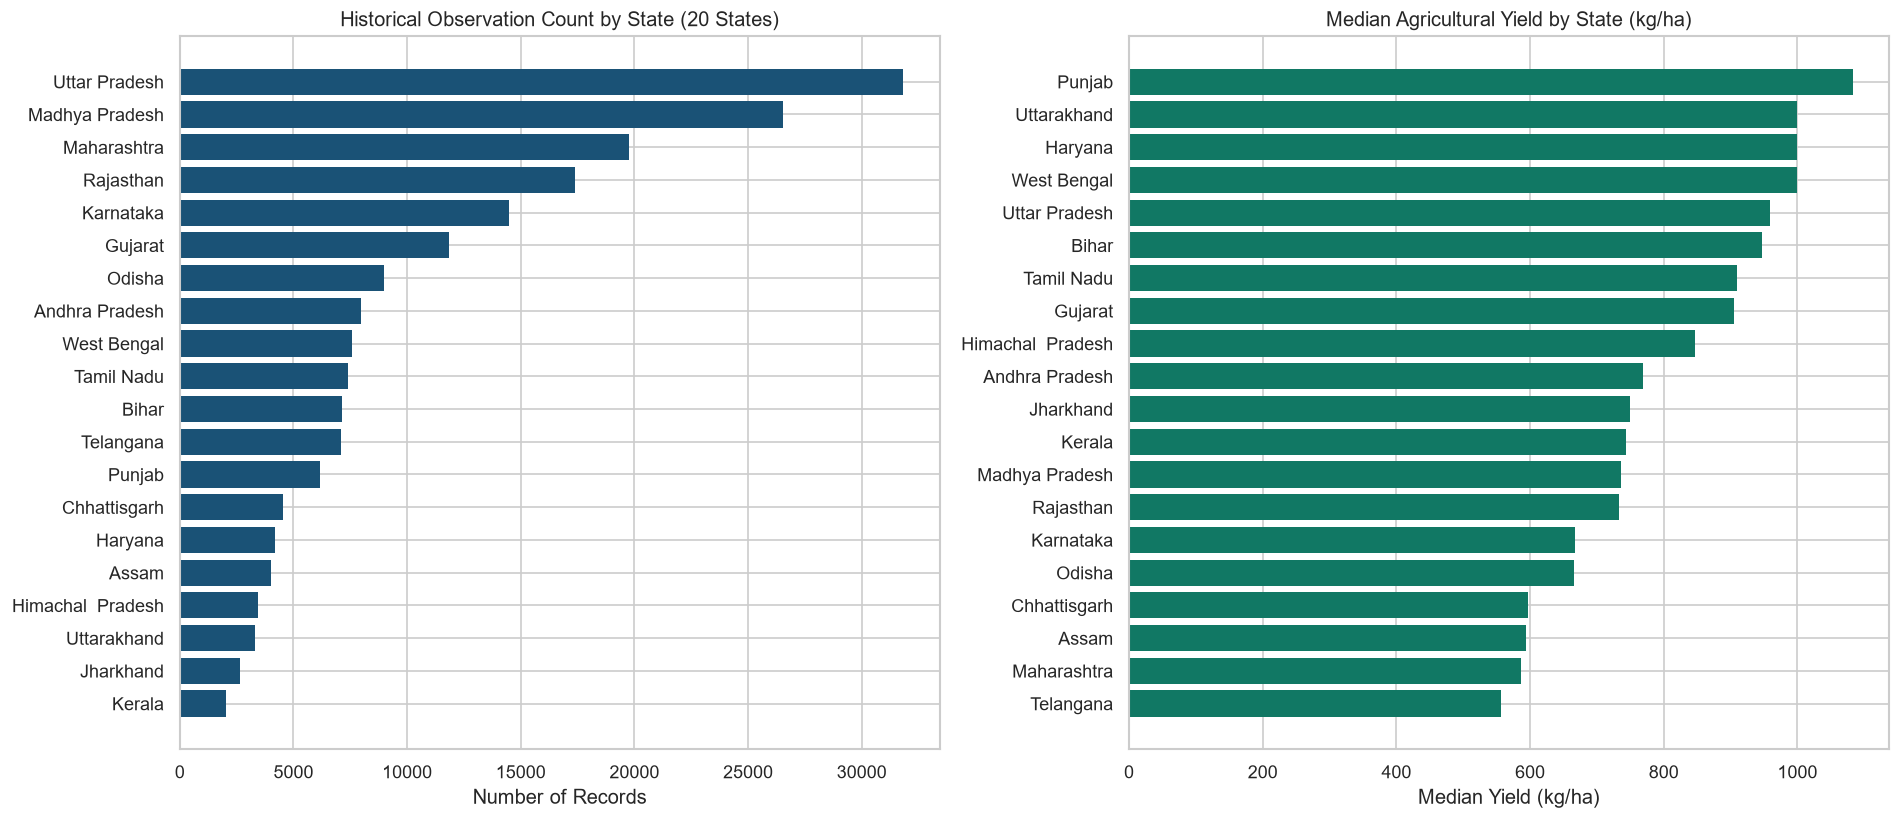

In [14]:
# Figure 6: State-Level Observation Counts and Median Yield
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot A: Observation Count by State
axes[0].barh(state_summary["State"][::-1], state_summary["Record_Count"][::-1], color="#1a5276", edgecolor="none")
axes[0].set_title("Historical Observation Count by State (20 States)")
axes[0].set_xlabel("Number of Records")

# Subplot B: Median Yield by State
state_yield_sorted = state_summary.sort_values("Median_Yield", ascending=True)
axes[1].barh(state_yield_sorted["State"], state_yield_sorted["Median_Yield"], color="#117864", edgecolor="none")
axes[1].set_title("Median Agricultural Yield by State (kg/ha)")
axes[1].set_xlabel("Median Yield (kg/ha)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig06_state_level_summary.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


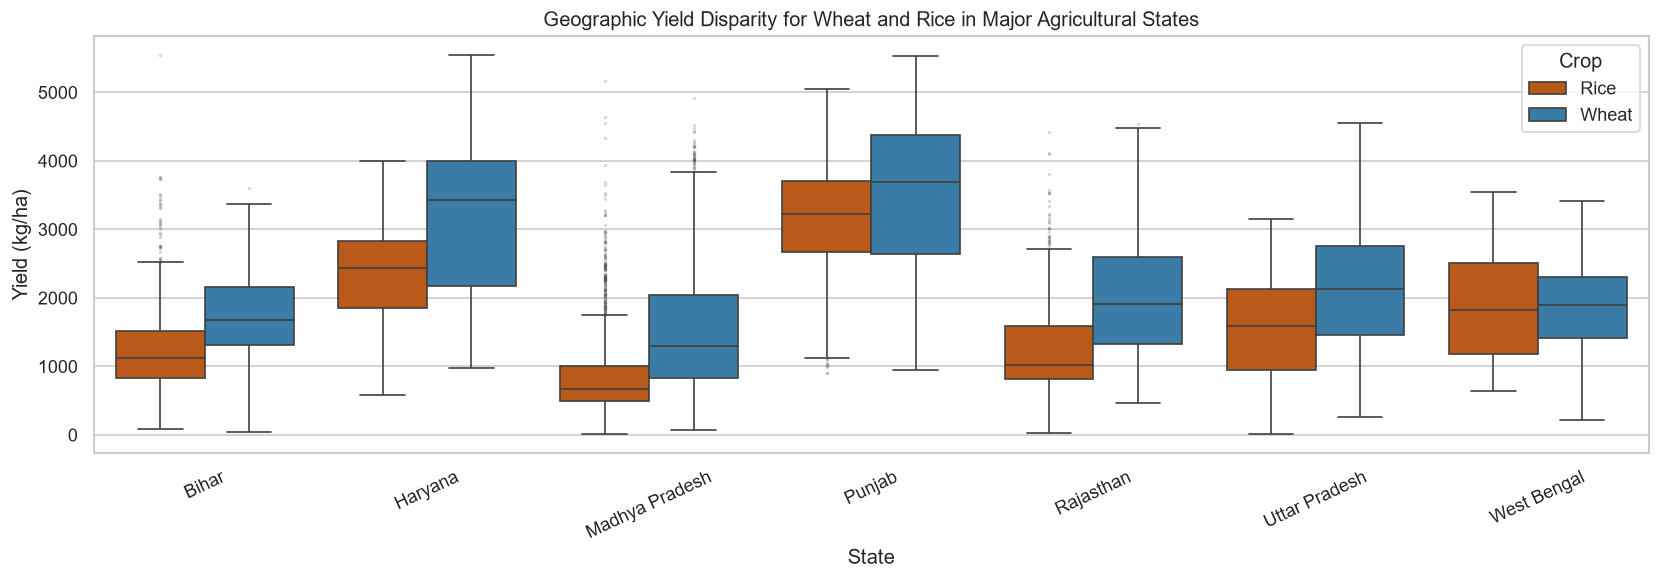

In [15]:
# Figure 7: Geographic Variation for Staples (Wheat and Rice across Top States)
staple_df = df[df["Crop"].isin(["Wheat", "Rice"]) & df["State"].isin(["Punjab", "Haryana", "Uttar Pradesh", "Bihar", "West Bengal", "Madhya Pradesh", "Rajasthan"])]

plt.figure(figsize=(14, 5))
sns.boxplot(data=staple_df, x="State", y="Yield", hue="Crop", palette=["#d35400", "#2980b9"], flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})
plt.title("Geographic Yield Disparity for Wheat and Rice in Major Agricultural States")
plt.xlabel("State")
plt.ylabel("Yield (kg/ha)")
plt.xticks(rotation=25)
plt.legend(title="Crop")
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig07_geographic_crop_variation.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


## Climate Feature Analysis

We explore distributions and associations between climate features and yield. These observational curves are not causal response estimates.

In [16]:
# Climate statistical summary
climate_cols = ["Temperature", "Rainfall", "Humidity"]
climate_summary = df[climate_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
climate_summary["Skewness"] = df[climate_cols].skew().round(2)
climate_summary.to_csv(REPORTS_TAB_DIR / "07_climate_summary.csv")
display(climate_summary.round(2))


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,Skewness
Temperature,198369.0,25.58,2.52,-2.84,14.68,22.82,25.23,25.99,26.69,27.66,28.15,29.12,-5.70
Rainfall,198369.0,1019.97,579.87,7.00,195.10,364.20,662.10,903.30,1229.40,2059.70,3307.83,8409.00,2.21
Humidity,198369.0,54.44,11.48,24.60,31.90,37.30,46.00,53.10,62.60,75.40,79.00,83.40,0.28


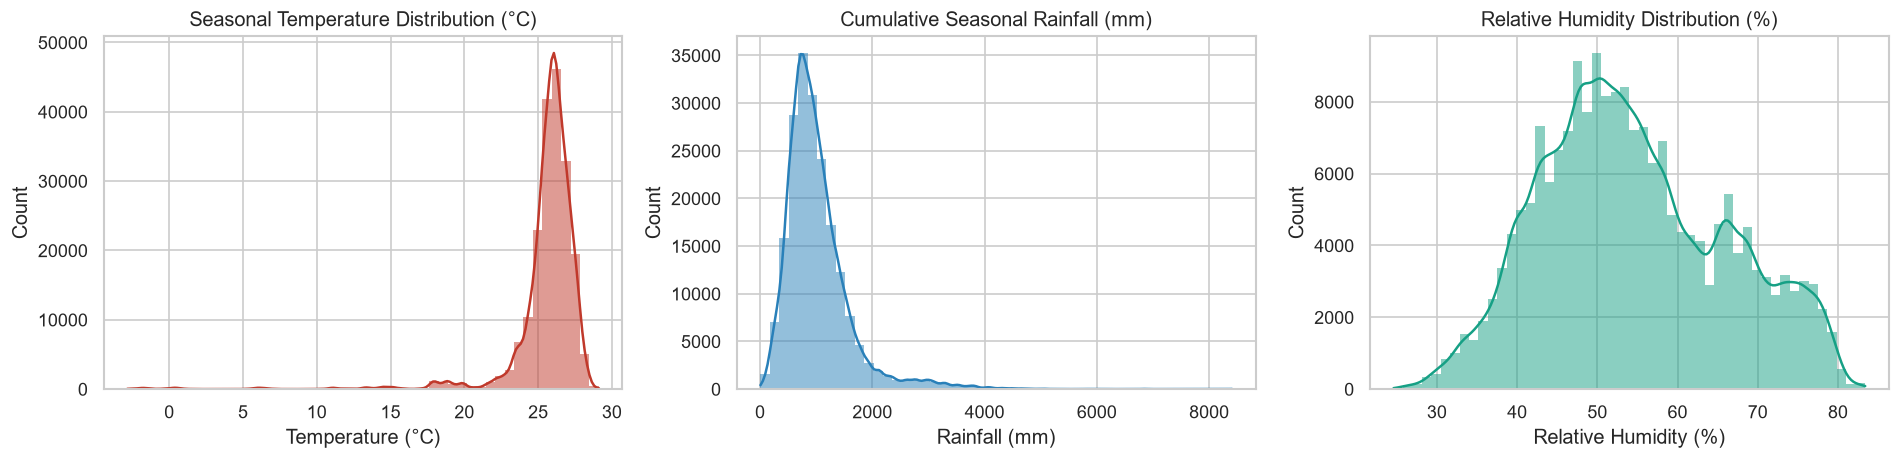

In [17]:
# Figure 8: Climate Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Temperature"], bins=50, kde=True, ax=axes[0], color="#c0392b", edgecolor="none")
axes[0].set_title("Seasonal Temperature Distribution (°C)")
axes[0].set_xlabel("Temperature (°C)")

sns.histplot(df["Rainfall"], bins=50, kde=True, ax=axes[1], color="#2980b9", edgecolor="none")
axes[1].set_title("Cumulative Seasonal Rainfall (mm)")
axes[1].set_xlabel("Rainfall (mm)")

sns.histplot(df["Humidity"], bins=50, kde=True, ax=axes[2], color="#16a085", edgecolor="none")
axes[2].set_title("Relative Humidity Distribution (%)")
axes[2].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig08_climate_distributions.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


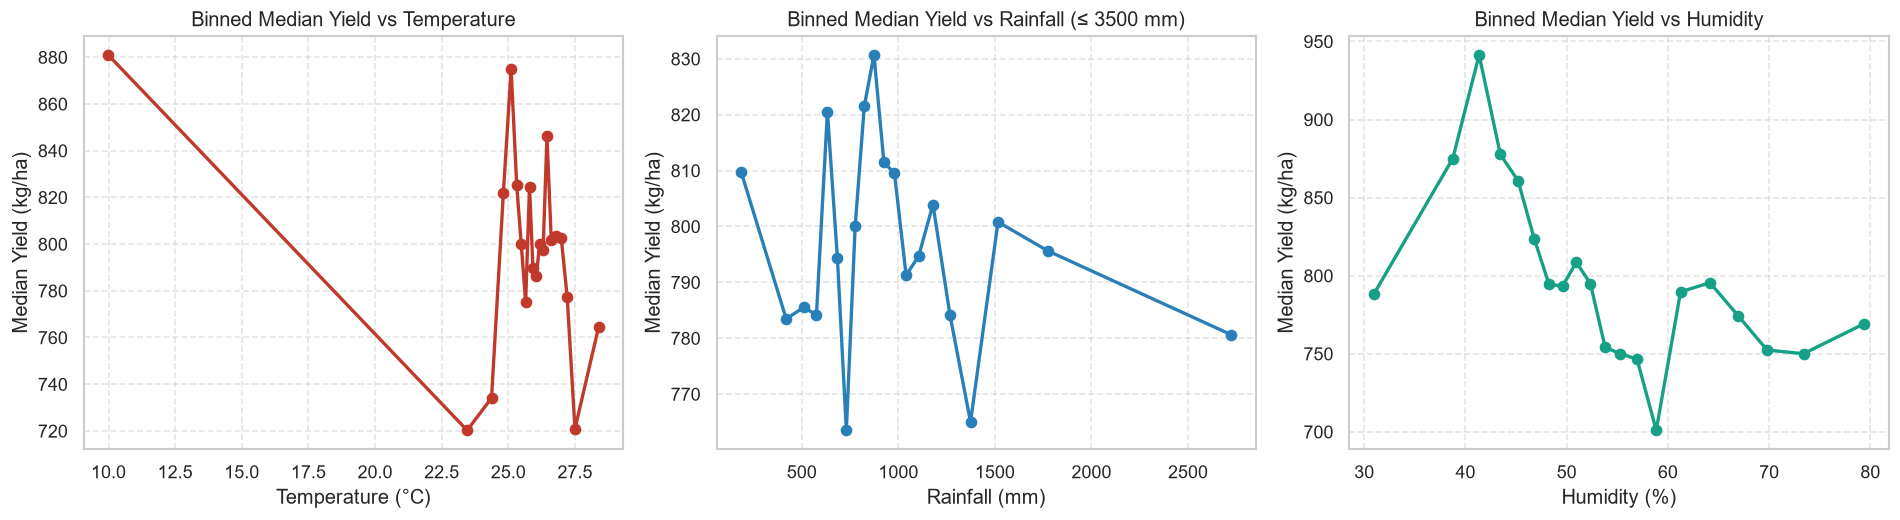

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_8776\123699048.py:41: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Temp_Bin", "Hum_Bin"], inplace=True)


In [18]:
# Figure 9: Binned Median Yield Response Curves across Climate Predictors
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Temperature Binned Median Yield
df["Temp_Bin"] = pd.qcut(df["Temperature"], q=20, duplicates="drop")
temp_binned = df.groupby("Temp_Bin", observed=True)["Yield"].median().reset_index()
temp_binned["Mid"] = temp_binned["Temp_Bin"].apply(lambda b: b.mid)
axes[0].plot(temp_binned["Mid"], temp_binned["Yield"], marker="o", color="#c0392b", lw=2.0)
axes[0].set_title("Binned Median Yield vs Temperature")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Median Yield (kg/ha)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Rainfall Binned Median Yield (up to 3500 mm for visibility)
df_rf_sub = df[df["Rainfall"] <= 3500].copy()
df_rf_sub["Rain_Bin"] = pd.qcut(df_rf_sub["Rainfall"], q=20, duplicates="drop")
rain_binned = df_rf_sub.groupby("Rain_Bin", observed=True)["Yield"].median().reset_index()
rain_binned["Mid"] = rain_binned["Rain_Bin"].apply(lambda b: b.mid)
axes[1].plot(rain_binned["Mid"], rain_binned["Yield"], marker="o", color="#2980b9", lw=2.0)
axes[1].set_title("Binned Median Yield vs Rainfall (≤ 3500 mm)")
axes[1].set_xlabel("Rainfall (mm)")
axes[1].set_ylabel("Median Yield (kg/ha)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Humidity Binned Median Yield
df["Hum_Bin"] = pd.qcut(df["Humidity"], q=20, duplicates="drop")
hum_binned = df.groupby("Hum_Bin", observed=True)["Yield"].median().reset_index()
hum_binned["Mid"] = hum_binned["Hum_Bin"].apply(lambda b: b.mid)
axes[2].plot(hum_binned["Mid"], hum_binned["Yield"], marker="o", color="#16a085", lw=2.0)
axes[2].set_title("Binned Median Yield vs Humidity")
axes[2].set_xlabel("Humidity (%)")
axes[2].set_ylabel("Median Yield (kg/ha)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig09_climate_vs_yield_binned.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

# Clean up temporary bin columns
df.drop(columns=["Temp_Bin", "Hum_Bin"], inplace=True)


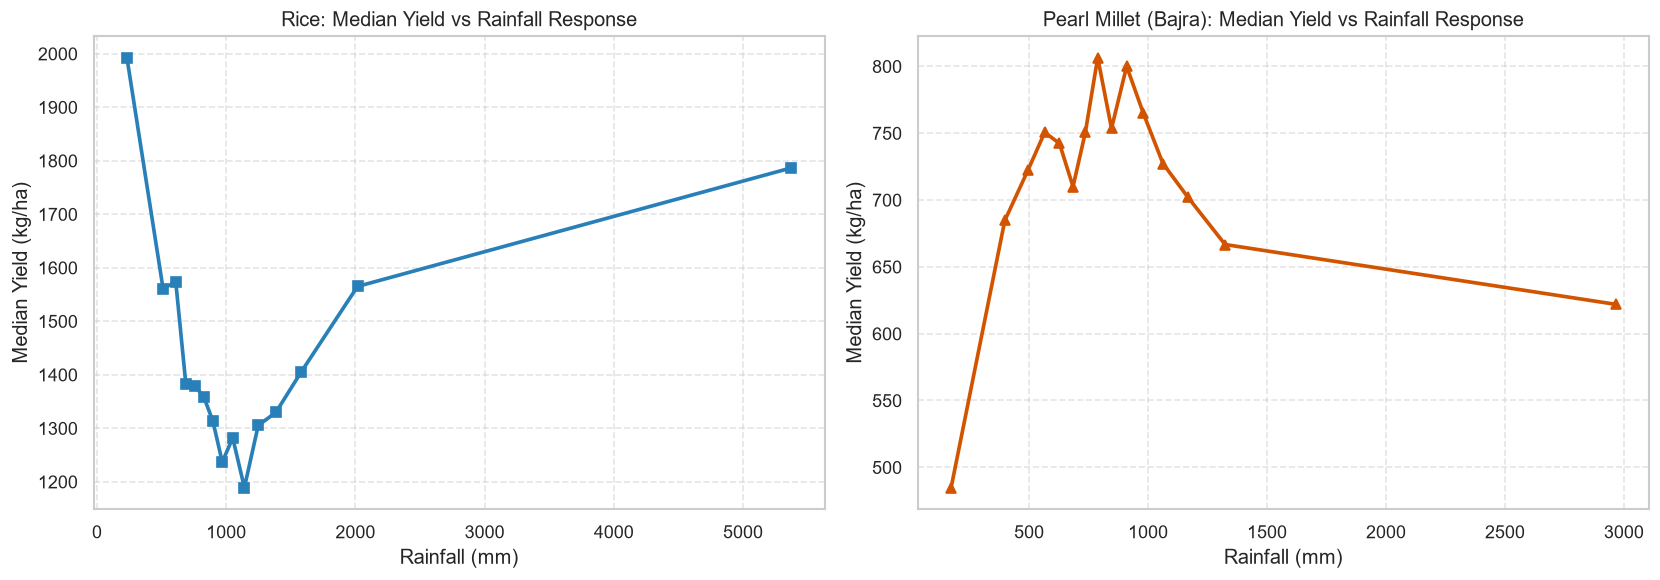

In [19]:
# Figure 10: Crop-Specific Climate Response Curves (Contrasting Rice vs Pearl Millet)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Rice Rainfall Response
rice_df = df[df["Crop"] == "Rice"].copy()
rice_df["Rain_Bin"] = pd.qcut(rice_df["Rainfall"], q=15, duplicates="drop")
rice_curve = rice_df.groupby("Rain_Bin", observed=True)["Yield"].median().reset_index()
rice_curve["Mid"] = rice_curve["Rain_Bin"].apply(lambda b: b.mid)

axes[0].plot(rice_curve["Mid"], rice_curve["Yield"], marker="s", color="#2980b9", lw=2.2)
axes[0].set_title("Rice: Median Yield vs Rainfall Response")
axes[0].set_xlabel("Rainfall (mm)")
axes[0].set_ylabel("Median Yield (kg/ha)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Pearl Millet Rainfall Response
bajra_df = df[df["Crop"] == "Pearl Millet"].copy()
bajra_df["Rain_Bin"] = pd.qcut(bajra_df["Rainfall"], q=15, duplicates="drop")
bajra_curve = bajra_df.groupby("Rain_Bin", observed=True)["Yield"].median().reset_index()
bajra_curve["Mid"] = bajra_curve["Rain_Bin"].apply(lambda b: b.mid)

axes[1].plot(bajra_curve["Mid"], bajra_curve["Yield"], marker="^", color="#d35400", lw=2.2)
axes[1].set_title("Pearl Millet (Bajra): Median Yield vs Rainfall Response")
axes[1].set_xlabel("Rainfall (mm)")
axes[1].set_ylabel("Median Yield (kg/ha)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig10_crop_climate_responses.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Climate interpretation:** The shapes of the pooled and crop-specific curves may differ. We treat these as associations that can be affected by geography, time and crop composition; we do not infer an optimal rainfall level from these figures alone.


## Soil Characteristics

We examine soil categories, pH distributions and pooled yield patterns. The value of pH beyond Soil Type remains a modeling question.

In [20]:
# Soil Type and pH Summary
soil_summary = df.groupby("Soil Type").agg(
    Record_Count=("Yield", "count"),
    Mean_Yield=("Yield", "mean"),
    Median_Yield=("Yield", "median"),
    Mean_pH=("pH", "mean"),
    Median_pH=("pH", "median"),
    Std_pH=("pH", "std"),
    Min_pH=("pH", "min"),
    Max_pH=("pH", "max")
).sort_values("Record_Count", ascending=False).reset_index()

soil_summary.to_csv(REPORTS_TAB_DIR / "08_soil_ph_summary.csv", index=False)
display(soil_summary)


,Soil Type,Record_Count,Mean_Yield,Median_Yield,Mean_pH,Median_pH,Std_pH,Min_pH,Max_pH
0,Vertisols,66575,1074.054621,682.980,7.599010,7.6,0.138974,6.9,7.82
1,Inceptisols,57113,1362.353610,968.750,6.780325,6.8,0.121236,5.6,6.96
2,Alfisols,34266,1320.235728,714.290,6.367528,6.2,0.297342,6.0,7.14
3,Mollisols,18508,1103.794201,781.825,7.090825,7.2,0.195150,6.6,7.36
4,Aridisols,13365,1625.781953,947.370,7.670768,7.8,0.356507,7.1,8.00
5,Entisols,8542,1066.864699,734.300,6.563395,6.5,0.216164,6.5,7.40


C:\Users\PHITESH\AppData\Local\Temp\ipykernel_8776\3330700681.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Soil Type", y="pH", ax=axes[1], palette="Set3")


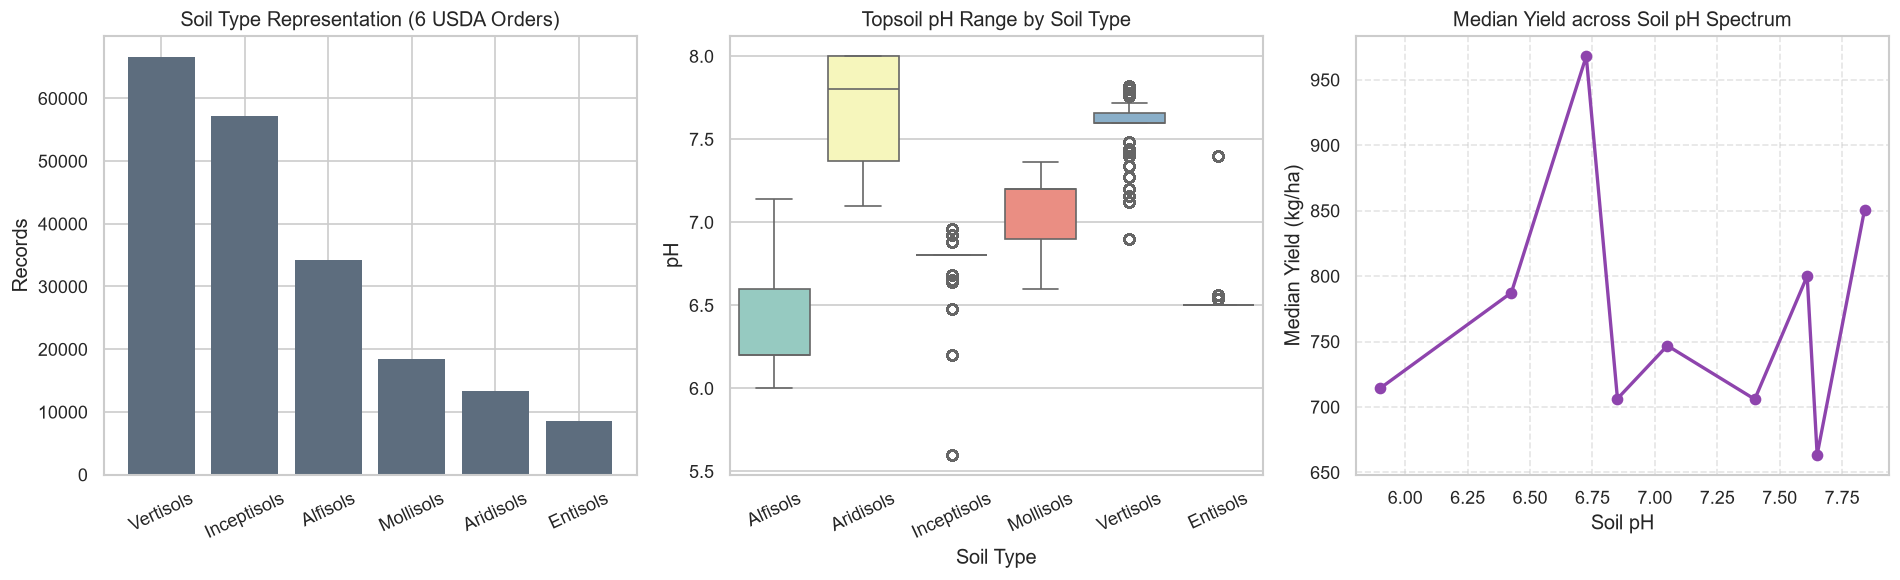

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_8776\3330700681.py:31: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["pH_Bin"], inplace=True)


In [21]:
# Figure 11: Soil Characteristics and pH Distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Subplot A: Soil Type Record Count
axes[0].bar(soil_summary["Soil Type"], soil_summary["Record_Count"], color="#5d6d7e", edgecolor="none")
axes[0].set_title("Soil Type Representation (6 USDA Orders)")
axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=25)

# Subplot B: pH Distribution by Soil Type
sns.boxplot(data=df, x="Soil Type", y="pH", ax=axes[1], palette="Set3")
axes[1].set_title("Topsoil pH Range by Soil Type")
axes[1].set_ylabel("pH")
axes[1].tick_params(axis="x", rotation=25)

# Subplot C: Binned Median Yield vs pH
df["pH_Bin"] = pd.qcut(df["pH"], q=10, duplicates="drop")
ph_binned = df.groupby("pH_Bin", observed=True)["Yield"].median().reset_index()
ph_binned["Mid"] = ph_binned["pH_Bin"].apply(lambda b: b.mid)
axes[2].plot(ph_binned["Mid"], ph_binned["Yield"], marker="o", color="#8e44ad", lw=2.0)
axes[2].set_title("Median Yield across Soil pH Spectrum")
axes[2].set_xlabel("Soil pH")
axes[2].set_ylabel("Median Yield (kg/ha)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig11_soil_and_ph.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

df.drop(columns=["pH_Bin"], inplace=True)


**Soil interpretation:** Soil Type and pH may contain overlapping information. We will test their incremental predictive value during chronological validation rather than assuming either is redundant.


## Nutrient Input Patterns

We examine nutrient distributions and changes over time. The near-identity between Fertilizer and N + P + K was documented in the data audit.

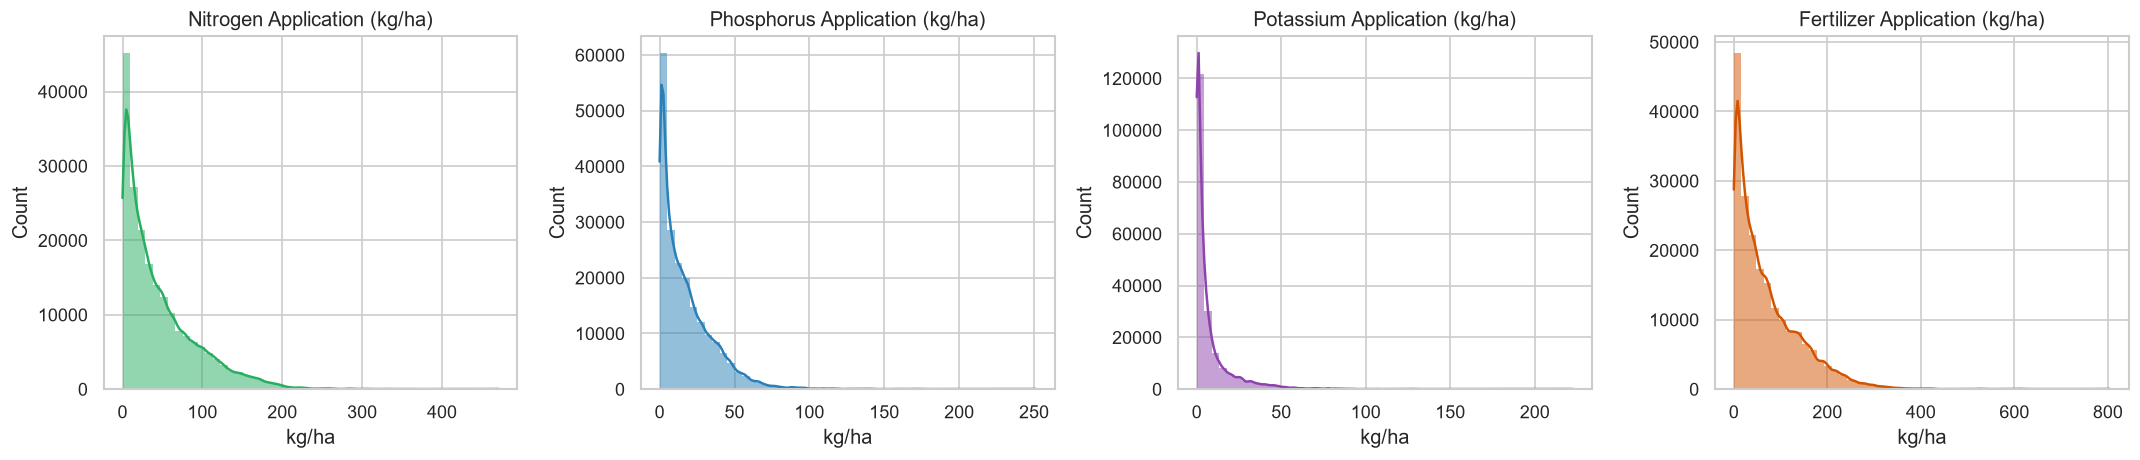

In [22]:
# Figure 12: Nutrient Distributions
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
nutrient_cols = ["Nitrogen", "Phosphorus", "Potassium", "Fertilizer"]
colors = ["#27ae60", "#2980b9", "#8e44ad", "#d35400"]

for ax, col, c in zip(axes, nutrient_cols, colors):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color=c, edgecolor="none")
    ax.set_title(f"{col} Application (kg/ha)")
    ax.set_xlabel("kg/ha")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig12_nutrient_distributions.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


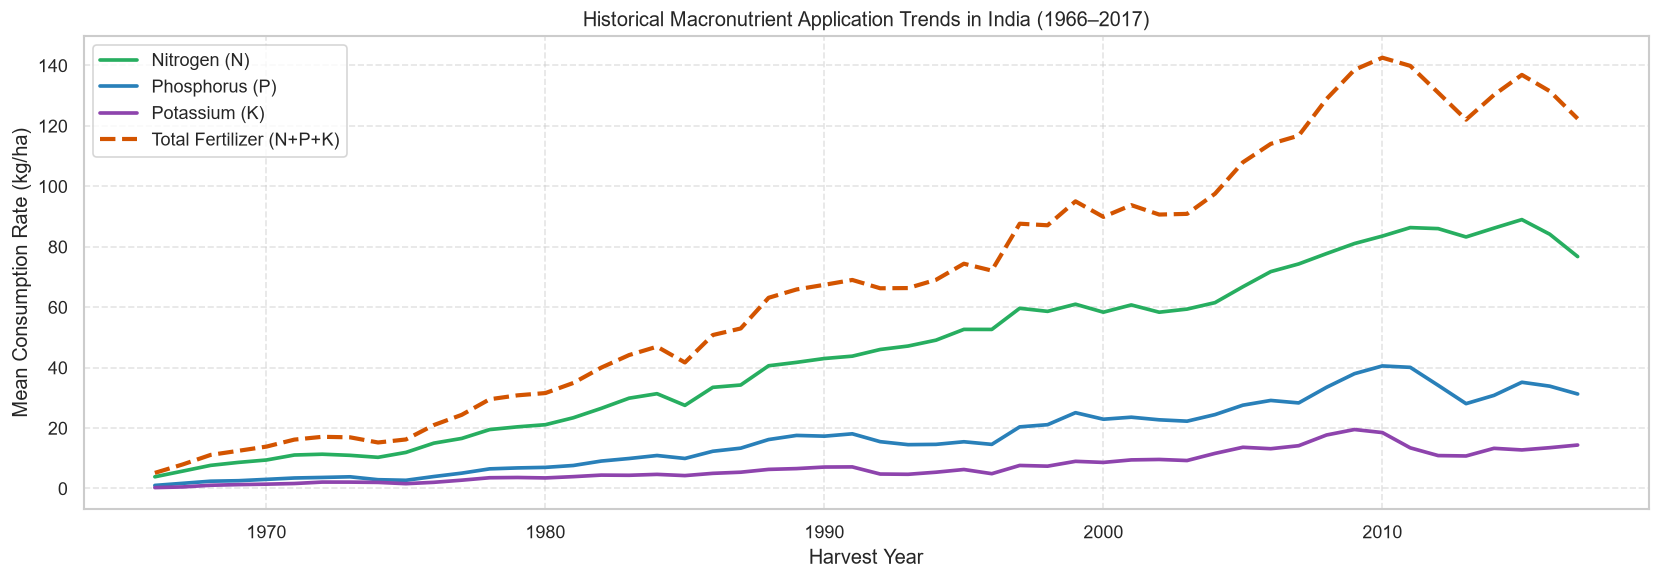

In [23]:
# Figure 14: Historical Growth of Nutrient Application Rates (1966–2017)
annual_nutrients = df.groupby("Year")[["Nitrogen", "Phosphorus", "Potassium", "Fertilizer"]].mean().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(annual_nutrients["Year"], annual_nutrients["Nitrogen"], label="Nitrogen (N)", color="#27ae60", lw=2.2)
plt.plot(annual_nutrients["Year"], annual_nutrients["Phosphorus"], label="Phosphorus (P)", color="#2980b9", lw=2.2)
plt.plot(annual_nutrients["Year"], annual_nutrients["Potassium"], label="Potassium (K)", color="#8e44ad", lw=2.2)
plt.plot(annual_nutrients["Year"], annual_nutrients["Fertilizer"], label="Total Fertilizer (N+P+K)", color="#d35400", lw=2.5, linestyle="--")
plt.title("Historical Macronutrient Application Trends in India (1966–2017)")
plt.xlabel("Harvest Year")
plt.ylabel("Mean Consumption Rate (kg/ha)")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig14_nutrient_trends_over_time.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Nutrient interpretation:** Nutrient and total fertilizer values vary over time. Because total Fertilizer is approximately the sum of N, P and K, we will compare alternative nutrient feature sets during modeling.


### Measurement and interpretation note

Several inputs were assembled or backfilled from sources with different spatial and temporal resolution. A complete CSV does not imply that every weather, soil, or management field is a direct measurement for the district–crop–year. In particular, soil pH is partly derived and pesticide usage is a national annual indicator. These limitations must be considered when interpreting relationships and designing the future prediction interface.

## Pesticide Indicator: National-Level Variation

The dataset's `Pesticide` column represents a national annual indicator rather than a district-specific treatment. We verify whether each year has only one value, plot the historical pattern, and avoid interpreting it as local pesticide use. The predictor's usefulness will be evaluated in the later **feature-selection** notebook, not decided here.

,Year,Records,Unique_Values,Pesticide
0,1966,3213,1,0.44
1,1967,3108,1,0.44
2,1968,3205,1,0.44
3,1969,3311,1,0.44
4,1970,3401,1,0.44


Maximum unique Pesticide values within any year: 1
Distinct Pesticide values in full dataset: 16


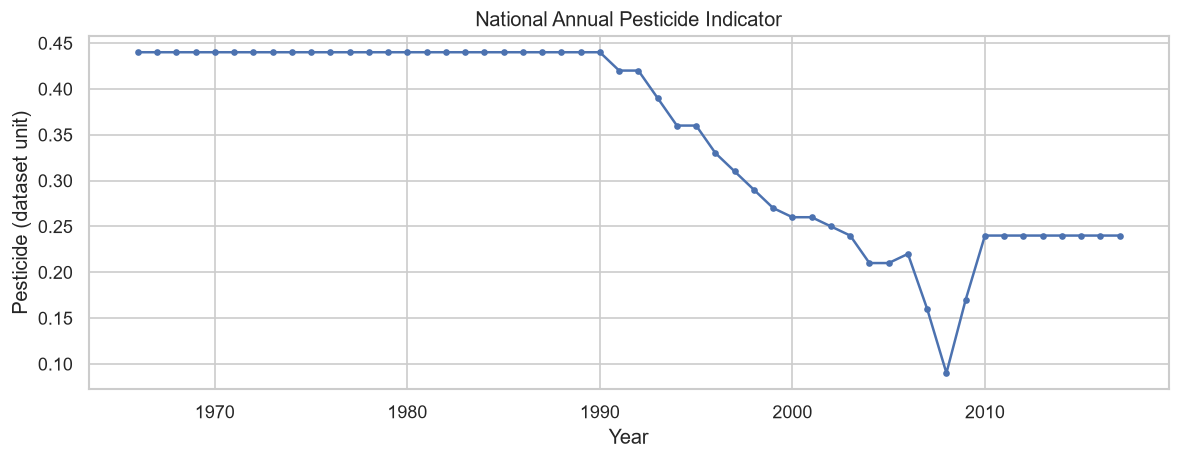

In [24]:
# Verify national-year aggregation and examine the historical pattern
pesticide_yearly = (df.groupby("Year")["Pesticide"]
                    .agg(Records="size", Unique_Values="nunique", Pesticide="first")
                    .reset_index())
display(pesticide_yearly.head())
print("Maximum unique Pesticide values within any year:", pesticide_yearly["Unique_Values"].max())
print("Distinct Pesticide values in full dataset:", df["Pesticide"].nunique())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pesticide_yearly["Year"], pesticide_yearly["Pesticide"], marker=".")
ax.set(title="National Annual Pesticide Indicator", xlabel="Year", ylabel="Pesticide (dataset unit)")
plt.tight_layout()
plt.show()

pesticide_yearly.to_csv(REPORTS_TAB_DIR / "10_pesticide_annual_values.csv", index=False)

**Interpretation:** Identical values within each year cannot explain district-to-district differences in pesticide application. Since the source compilation may include backfills, this field is better treated as a historical national proxy—not as an input a farmer should be required to provide.

## Correlation and Multicollinearity

We explore pairwise Pearson and Spearman correlations for numeric features. Correlation does not establish causation or feature importance.

In [25]:
# Compute Pearson and Spearman Correlation Matrices
numeric_cols = ["Year", "Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Fertilizer", "Pesticide", "Yield"]

corr_pearson = df[numeric_cols].corr(method="pearson")
corr_spearman = df[numeric_cols].corr(method="spearman")

corr_pearson.to_csv(REPORTS_TAB_DIR / "11_correlation_matrix.csv")

# Extract Highly Collinear Feature Pairs (|Pearson r| >= 0.70, excluding self-correlation)
high_corr_pairs = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        col1 = numeric_cols[i]
        col2 = numeric_cols[j]
        r_val = corr_pearson.loc[col1, col2]
        if abs(r_val) >= 0.70:
            high_corr_pairs.append({
                "Feature 1": col1,
                "Feature 2": col2,
                "Pearson r": round(r_val, 4),
                "Spearman rho": round(corr_spearman.loc[col1, col2], 4),
                "Nature of Relationship": "Algebraic Redundancy" if ("Fertilizer" in [col1, col2] and any(n in [col1, col2] for n in ["Nitrogen", "Phosphorus", "Potassium"])) else "Statistical Association"
            })

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values("Pearson r", ascending=False)
df_high_corr.to_csv(REPORTS_TAB_DIR / "12_highly_correlated_pairs.csv", index=False)
display(df_high_corr)


,Feature 1,Feature 2,Pearson r,Spearman rho,Nature of Relationship
2,Nitrogen,Fertilizer,0.9690,0.9873,Algebraic Redundancy
3,Phosphorus,Fertilizer,0.9373,0.9560,Algebraic Redundancy
1,Nitrogen,Phosphorus,0.8512,0.9128,Statistical Association
0,Year,Pesticide,-0.8779,-0.9130,Statistical Association


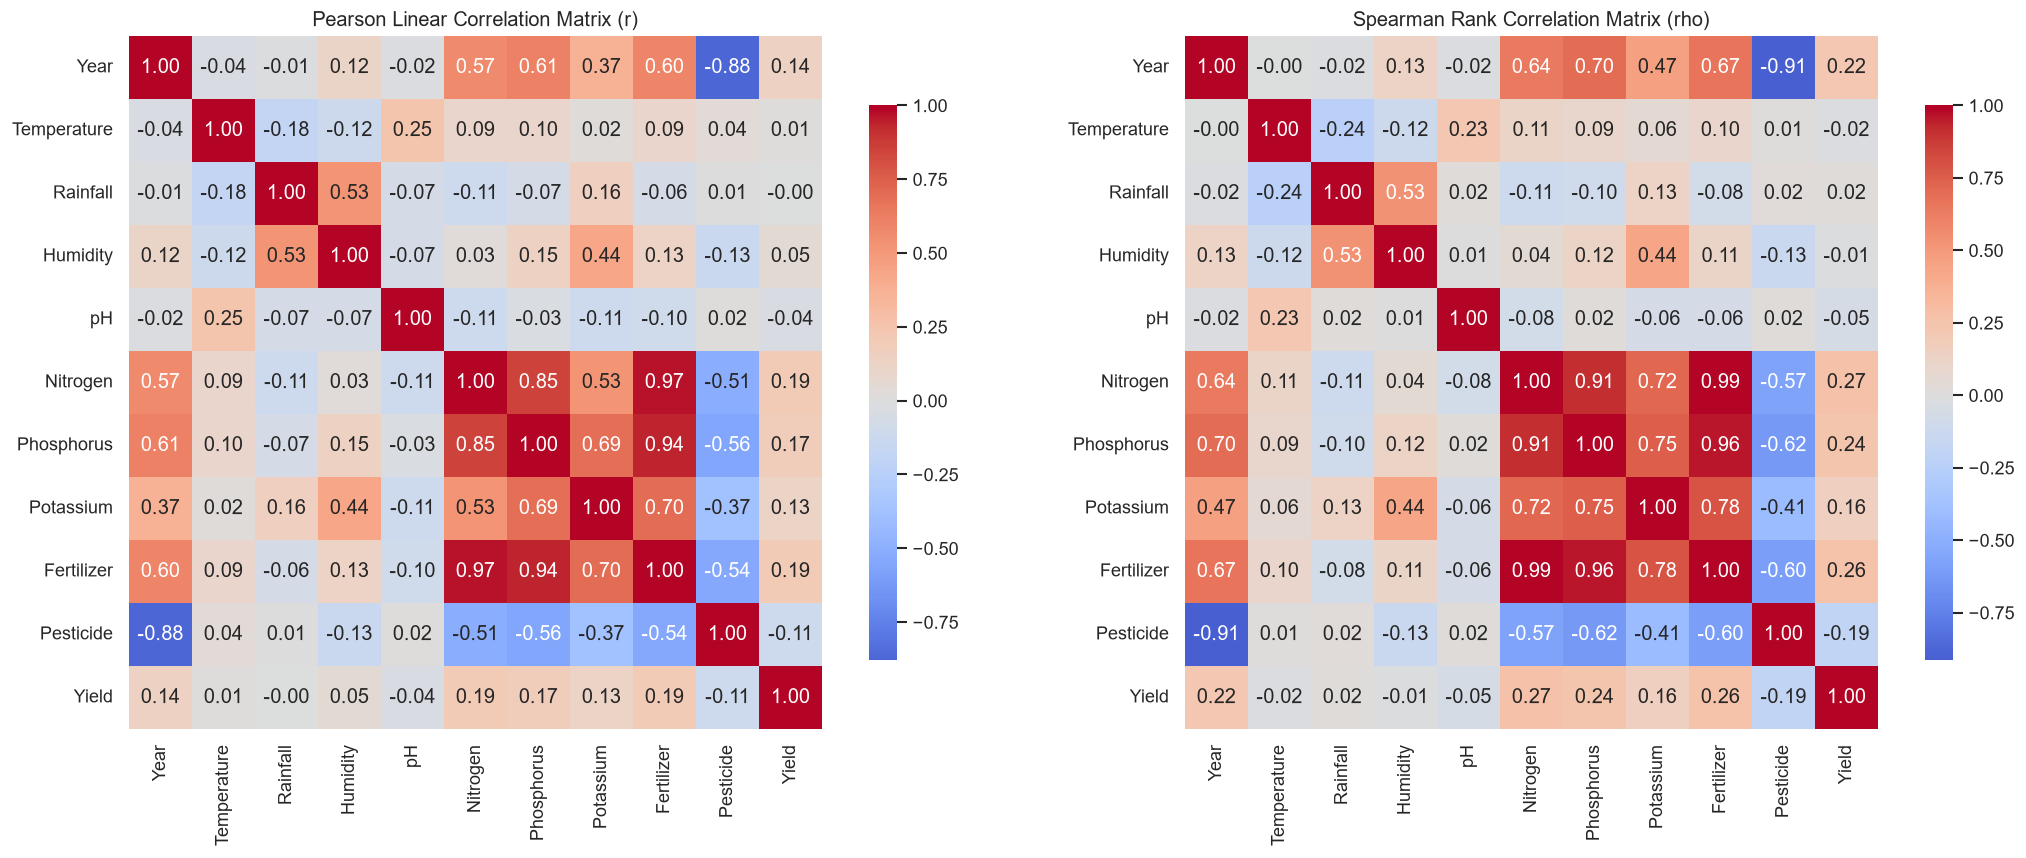

In [26]:
# Figure 16: Heatmaps of Pearson and Spearman Correlations
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Pearson Heatmap
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar_kws={"shrink": 0.8}, square=True)
axes[0].set_title("Pearson Linear Correlation Matrix (r)")

# Spearman Heatmap
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": 0.8}, square=True)
axes[1].set_title("Spearman Rank Correlation Matrix (rho)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig16_correlation_heatmaps.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


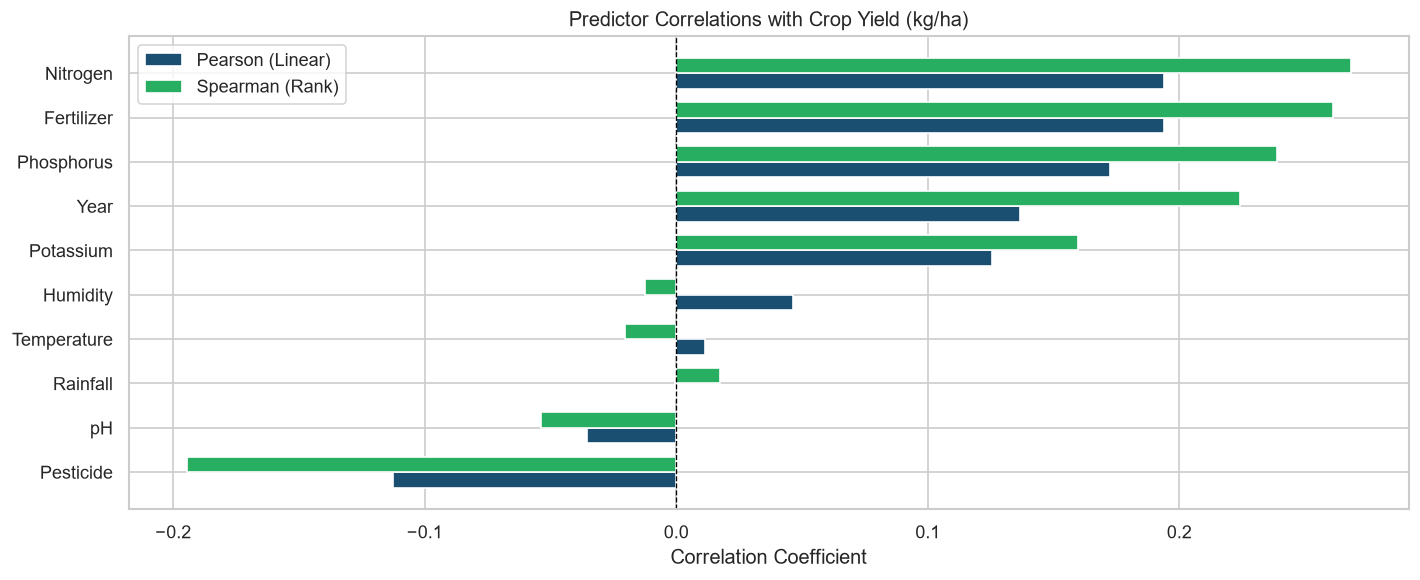

In [27]:
# Figure 17: Feature Correlation with Target Yield (Pearson vs Spearman)
target_corr = pd.DataFrame({
    "Pearson": corr_pearson["Yield"].drop("Yield"),
    "Spearman": corr_spearman["Yield"].drop("Yield")
}).sort_values("Pearson", ascending=True)

plt.figure(figsize=(12, 5))
x = np.arange(len(target_corr))
width = 0.35

plt.barh(x - width/2, target_corr["Pearson"], width, label="Pearson (Linear)", color="#1b4f72")
plt.barh(x + width/2, target_corr["Spearman"], width, label="Spearman (Rank)", color="#27ae60")
plt.yticks(x, target_corr.index)
plt.title("Predictor Correlations with Crop Yield (kg/ha)")
plt.xlabel("Correlation Coefficient")
plt.axvline(0, color="black", lw=0.8, linestyle="--")
plt.legend()
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig17_correlation_with_yield.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Correlation interpretation:** Strong correlations identify potential redundant inputs, but weak marginal correlations do not imply a feature is useless. The correlations are pooled across crops and years.


## Climate and Fertilizer Interactions

We visualize pooled temperature–rainfall patterns and crop-specific fertilizer associations. These are descriptive, not estimates of an optimal treatment.

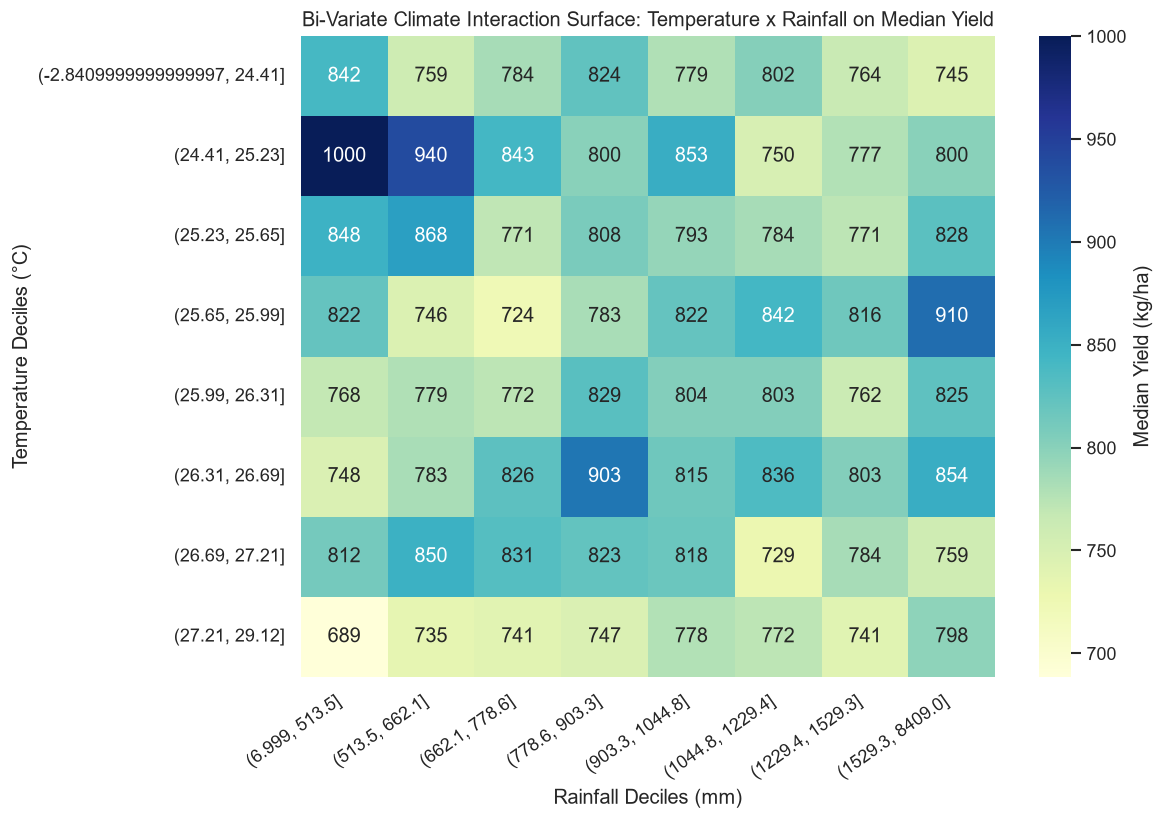

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_8776\4242243382.py:20: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Rain_Decile", "Temp_Decile"], inplace=True)


In [28]:
# Figure 18: 2D Interaction Surface of Rainfall x Temperature on Yield
# Bin Rainfall and Temperature into deciles and compute median yield
df["Rain_Decile"] = pd.qcut(df["Rainfall"], q=8, duplicates="drop")
df["Temp_Decile"] = pd.qcut(df["Temperature"], q=8, duplicates="drop")

pivot_climate_yield = df.pivot_table(index="Temp_Decile", columns="Rain_Decile", values="Yield", aggfunc="median", observed=True)

plt.figure(figsize=(10, 7))
sns.heatmap(pivot_climate_yield, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={"label": "Median Yield (kg/ha)"})
plt.title("Bi-Variate Climate Interaction Surface: Temperature x Rainfall on Median Yield")
plt.xlabel("Rainfall Deciles (mm)")
plt.ylabel("Temperature Deciles (°C)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig18_rainfall_temp_interaction.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

df.drop(columns=["Rain_Decile", "Temp_Decile"], inplace=True)


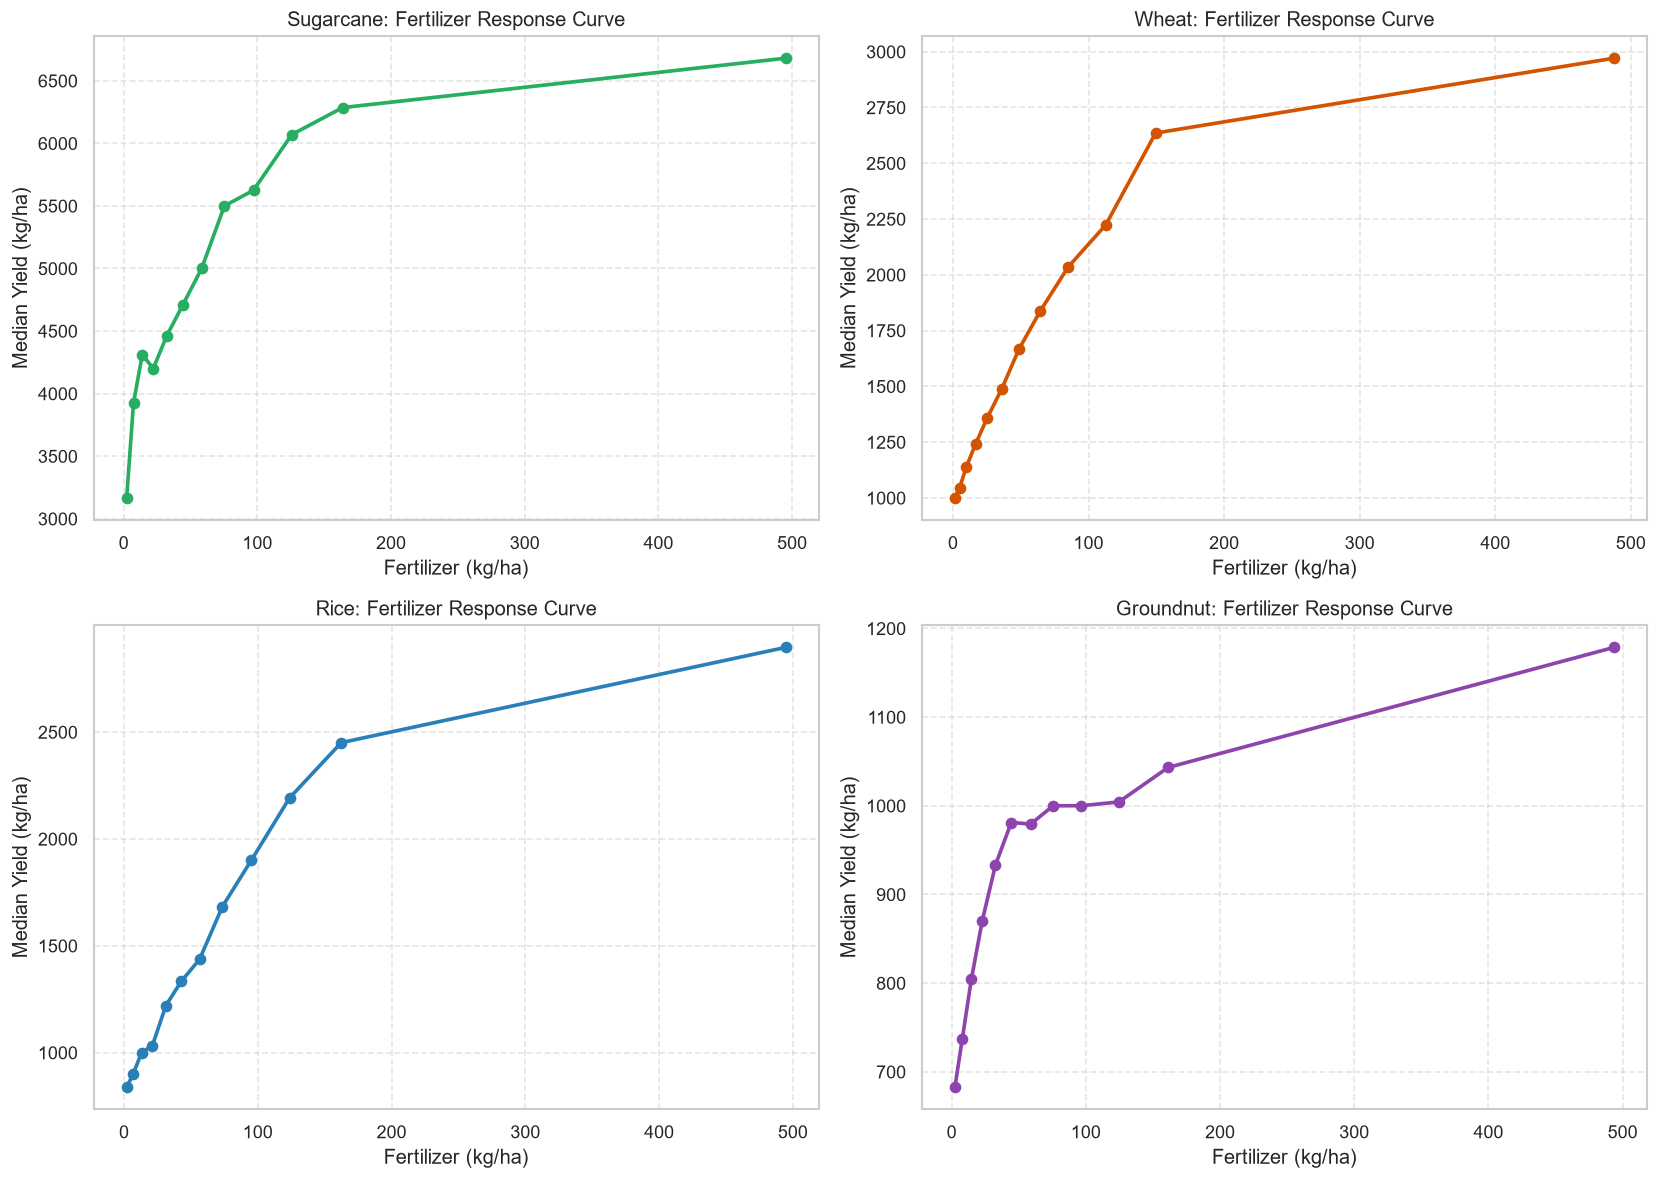

In [29]:
# Figure 19: Fertilizer vs Yield Curves Faceted by Major Crops
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
crops_to_facet = ["Sugarcane", "Wheat", "Rice", "Groundnut"]
colors_facet = ["#27ae60", "#d35400", "#2980b9", "#8e44ad"]

for ax, c, col in zip(axes.flat, crops_to_facet, colors_facet):
    c_df = df[df["Crop"] == c].copy()
    c_df["Fert_Bin"] = pd.qcut(c_df["Fertilizer"], q=12, duplicates="drop")
    f_curve = c_df.groupby("Fert_Bin", observed=True)["Yield"].median().reset_index()
    f_curve["Mid"] = f_curve["Fert_Bin"].apply(lambda b: b.mid)
    
    ax.plot(f_curve["Mid"], f_curve["Yield"], marker="o", color=col, lw=2.2)
    ax.set_title(f"{c}: Fertilizer Response Curve")
    ax.set_xlabel("Fertilizer (kg/ha)")
    ax.set_ylabel("Median Yield (kg/ha)")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig19_crop_fertilizer_interactions.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Interaction interpretation:** The plotted relationships are observational and may reflect unmeasured differences between locations and years. We do not treat peaks as proven optimal growing conditions.


## Crop-Specific Outlier Candidates

We use per-crop IQR thresholds to flag observations for review, not to declare them erroneous or automatically exclude them.

In [30]:
# Identify crop-specific outlier thresholds
outlier_candidates = []

for c, grp in df.groupby("Crop"):
    q25 = grp["Yield"].quantile(0.25)
    q75 = grp["Yield"].quantile(0.75)
    iqr = q75 - q25
    mild_upper = q75 + 1.5 * iqr
    extreme_upper = q75 + 3.0 * iqr
    
    n_mild = (grp["Yield"] > mild_upper).sum()
    n_extreme = (grp["Yield"] > extreme_upper).sum()
    max_val = grp["Yield"].max()
    
    outlier_candidates.append({
        "Crop": c,
        "Total_Records": len(grp),
        "Median_Yield": round(grp["Yield"].median(), 2),
        "Mild_Threshold (1.5x)": round(mild_upper, 2),
        "Extreme_Threshold (3.0x)": round(extreme_upper, 2),
        "Mild_Outlier_Count": n_mild,
        "Extreme_Outlier_Count": n_extreme,
        "Max_Yield": round(max_val, 2),
        "Max/Median Ratio": round(max_val / grp["Yield"].median(), 2)
    })

df_outliers = pd.DataFrame(outlier_candidates).sort_values("Max/Median Ratio", ascending=False)
df_outliers.to_csv(REPORTS_TAB_DIR / "13_outlier_candidates_summary.csv", index=False)
display(df_outliers.head(10))


,Crop,Total_Records,Median_Yield,Mild_Threshold (1.5x),Extreme_Threshold (3.0x),Mild_Outlier_Count,Extreme_Outlier_Count,Max_Yield,Max/Median Ratio
2,Chickpea,13473,674.60,1574.32,2218.92,244,27,58363.64,86.52
8,Minor Pulses,13302,451.16,1183.35,1712.88,464,167,18888.89,41.87
3,Cotton,7600,212.50,647.33,961.32,252,71,5000.00,23.53
6,Linseed,6755,333.33,883.96,1267.92,452,50,7000.00,21.00
10,Pigeonpea,12668,700.00,1698.57,2417.71,398,95,12402.60,17.72
7,Maize,13615,1302.43,3624.34,5248.67,700,249,21428.57,16.45
14,Sesamum,12862,272.73,776.67,1139.39,558,34,4400.00,16.13
9,Pearl Millet,9796,721.28,1983.04,2892.50,373,36,10000.00,13.86
16,Sorghum (Rabi),3948,726.95,1750.00,2500.00,292,139,9578.95,13.18
11,Rapeseed & Mustard,11196,605.90,1735.06,2536.09,166,14,7000.00,11.55


**Outlier interpretation:** Crop-specific IQR thresholds identify candidate observations only. We preserve the source CSV and will test any justified training-only treatment without altering validation or test targets.


### Verify exceptional Chickpea observations

Earlier versions of the project mentioned inconsistent locations and years for the largest Chickpea yield. The table below derives the actual region, year and yield from the CSV, rather than repeating unverified descriptions. These observations are **candidates for source verification**, not automatically proven errors.

In [31]:
chickpea_extremes = (df.loc[df["Crop"].eq("Chickpea"), ["Year", "Region", "Crop", "Yield"]]
                      .sort_values("Yield", ascending=False).head(10))
display(chickpea_extremes)
print("Chickpea observations above 5,000 kg/ha:",
      int(((df["Crop"] == "Chickpea") & (df["Yield"] > 5000)).sum()))

,Year,Region,Crop,Yield
15772,2007,"Muzaffarpur, Bihar",Chickpea,58363.64
17654,2007,"Saharsa, Bihar",Chickpea,32000.00
36047,2017,"Ambala, Haryana",Chickpea,5000.00
137600,1968,"Sikar, Rajasthan",Chickpea,4833.33
39626,2016,"Rohtak, Haryana",Chickpea,4000.00
138506,1994,"Sirohi, Rajasthan",Chickpea,3140.04
36170,1975,"Gurgaon, Haryana",Chickpea,3065.81
1981,2005,"East Godavari, AndhraPradesh",Chickpea,3000.00
65752,2012,"Chhindwara, Madhya Pradesh",Chickpea,2828.83
65735,2011,"Chhindwara, Madhya Pradesh",Chickpea,2740.74


Chickpea observations above 5,000 kg/ha: 2


## Feature Availability for Future Prediction

Our first application must distinguish a **scenario estimate** from a genuine advance forecast:

| Feature category | Typical availability | Implication |
|---|---|---|
| Crop, district and year | Known when planning | Suitable low-input user choices |
| Soil Type, derived pH | Historical district-level reference | Can use documented reference values, not field-level measurements |
| Rainfall, temperature, humidity | Actual target-year values not known in advance | Require an external forecast or explicitly labeled user scenario |
| N, P, K, total fertilizer | May represent actual or aggregated applications | Require a documented planned-input assumption for advance use |
| Pesticide | National annual statistic | Not a sensible manual farmer input |

The historical model should not claim to forecast future yields from weather observations that are only known after the target season.

## EDA Summary and Modeling Considerations

We observe strong variation by crop, geography and year. We will use chronological evaluation (train: 1966–2011; validation: 2012–2014; test: 2015–2017), report per-crop performance, and compare raw and log-transformed yield targets. We will also evaluate feature redundancy for Season, Fertilizer and Pesticide rather than removing them by assumption. The two extreme Chickpea yields are flagged as suspected anomalies; the original CSV remains unchanged. Full-season measured weather and input variables support retrospective or scenario-based estimation, not an advance forecast unless those inputs are available beforehand.


**Next notebook:** `02_data_preparation.ipynb` will establish chronological splits and training-only preprocessing. It will not permanently discard predictors or implement feature selection. Research findings here are hypotheses to test on validation data.